# Injury Prediction for Competitive Runners
## Final Project — Introduction to Machine Learning | PL1-G4 | 2025/2026

---

### Research Questions

> **Primary**: What training patterns are most associated with injury risk, and do these differ between athlete subgroups?

> **Applied**: Can these patterns be used to build a day-by-day injury risk prediction system, and how should it be calibrated per athlete to be operationally useful?

The primary question drives the exploratory and analytical sections (4–6): we identify which features predict injury, cluster athletes into subgroups, and test whether risk factors differ between them. The applied question drives sections 7–9: we build a classifier, evaluate it honestly, and develop a personalised threshold strategy that makes the system usable in practice.

### Notebook Structure

| Section | Content |
|---|---|
| 1 | Data loading (from preprocessing pipeline) |
| 2 | Exploratory Data Analysis - athlete population, injury vs healthy profiles, PCA |
| 3 | Athlete Clustering - K-Means, subgroup injury rates |
| 4 | Feature Importance - global and per-cluster |
| 5 | Classification Models - 5 algorithms, balancing strategy, cross-validation, held-out evaluation |
| 6 | Case Study - day-by-day risk score for Athlete 9 |
| 7 | Personalised Thresholds - population-level alert system, model comparison |
| 8 | Ethical Considerations |
| 9 | Conclusions and Critical Reflection |

### AI Tool Acknowledgement
This project was developed with assistance from Claude (Anthropic) for code direction, methodological guidance, and iterative debugging. All decisions, including which analyses to include, how to interpret results, and which findings to report, were made and validated by the project team.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import json, os

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, roc_auc_score, average_precision_score,
                              classification_report, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from scipy import stats
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
os.makedirs('../figures/graphics_notebook', exist_ok=True)

df_raw       = pd.read_csv('../data/daily_injury_data.csv')
df_processed = pd.read_csv('../data/processed/df_processed.csv', index_col=0)
df_train     = pd.read_csv('../data/processed/df_train.csv', index_col=0)
df_test      = pd.read_csv('../data/processed/df_test.csv', index_col=0)
X_train      = pd.read_csv('../data/processed/X_train.csv', index_col=0)
X_test       = pd.read_csv('../data/processed/X_test.csv', index_col=0)
y_train      = pd.read_csv('../data/processed/y_train.csv', index_col=0).squeeze()
y_test       = pd.read_csv('../data/processed/y_test.csv', index_col=0).squeeze()

with open('../data/processed/feature_cols_acwr.json') as f:
    feature_cols_acwr = json.load(f)

print(f'Loaded: {len(df_processed):,} rows, {df_processed["Athlete ID"].nunique()} athletes')
print(f'Train: {len(X_train):,} rows | Test: {len(X_test):,} rows')
print(f'Injury rate — Train: {y_train.mean():.2%} | Test: {y_test.mean():.2%}')


Loaded: 42,766 rows, 74 athletes
Train: 35,022 rows | Test: 7,744 rows
Injury rate — Train: 1.24% | Test: 1.90%


---
## 2. Exploratory Data Analysis

Before building any model, we need to understand who these athletes are and what training looks like in the data. This section addresses the missing population description noted in the professor's Deliverable 2 feedback.

### Key questions:
- How are injury rates distributed across athletes?
- Do athletes with more training days get injured more?
- Does training frequency explain injury risk? (Kruskal-Wallis test)
- What does training look like on the days injuries happen vs healthy days?


In [2]:
# Per-athlete summary
athlete_profile = df_processed.groupby('Athlete ID').agg(
    total_days  = ('injury','count'),
    injury_days = ('injury','sum'),
).reset_index()
raw_agg = df_raw.groupby('Athlete ID').agg(
    avg_km_per_day = ('total km',           lambda x: x[x>0].mean()),
    pct_rest_days  = ('nr. sessions',       lambda x: (x==0).mean()),
    pct_strength   = ('strength training',  lambda x: (x>0).mean()),
    avg_exertion   = ('perceived exertion', lambda x: x[x>0].mean()),
    avg_recovery   = ('perceived recovery', lambda x: x[x>0].mean()),
).reset_index()
athlete_profile = athlete_profile.merge(raw_agg, on='Athlete ID')
athlete_profile['injury_rate']      = athlete_profile['injury_days'] / athlete_profile['total_days']
athlete_profile['injury_per_100d']  = athlete_profile['injury_rate'] * 100
athlete_profile['active_days_week'] = (1 - athlete_profile['pct_rest_days']) * 7

print('Population summary:')
print(f'  Athletes:               {len(athlete_profile)}')
print(f'  Avg days monitored:     {athlete_profile["total_days"].mean():.0f}')
print(f'  Athletes with injuries: {(athlete_profile["injury_days"]>0).sum()}')
print(f'  Avg injury rate:        {athlete_profile["injury_per_100d"].mean():.2f} per 100 days')
print(f'  Max injury rate:        {athlete_profile["injury_per_100d"].max():.2f} per 100 days')
print()
print(athlete_profile[['Athlete ID','total_days','injury_days',
                        'injury_per_100d','avg_km_per_day','active_days_week']].to_string())

# Pre-injury subjective values: do athletes report higher exertion / lower recovery before injury?
pre_injury_window = 14  # days before injury to analyse
pre_exertion, pre_recovery, baseline_exertion, baseline_recovery = [], [], [], []

for _, grp in df_processed.groupby('Athlete ID'):
    grp = grp.reset_index(drop=True)
    raw_grp = df_raw[df_raw['Athlete ID'] == grp['Athlete ID'].iloc[0]].reset_index(drop=True)
    for idx in grp.index[grp['injury'] == 1]:
        window = raw_grp.iloc[max(0, idx - pre_injury_window):idx]
        window = window[window['perceived exertion'] != -0.01]
        if len(window) >= 3:
            pre_exertion.append(window['perceived exertion'].mean())
            pre_recovery.append(window['perceived recovery'].mean())
    # Baseline: all non-injury, non-pre-injury days
    inj_idx = set(grp.index[grp['injury'] == 1])
    pre_idx = set()
    for i in inj_idx:
        pre_idx.update(range(max(0, i - pre_injury_window), i))
    baseline_idx = [i for i in grp.index if i not in inj_idx and i not in pre_idx]
    if baseline_idx:
        b = raw_grp.iloc[baseline_idx]
        b = b[b['perceived exertion'] != -0.01]
        if len(b) > 0:
            baseline_exertion.append(b['perceived exertion'].mean())
            baseline_recovery.append(b['perceived recovery'].mean())

print(f'Pre-injury ({pre_injury_window}d window) vs baseline subjective values:')
print(f'  Perceived exertion  — pre-injury: {np.nanmean(pre_exertion):.3f} | baseline: {np.nanmean(baseline_exertion):.3f}')
print(f'  Perceived recovery  — pre-injury: {np.nanmean(pre_recovery):.3f} | baseline: {np.nanmean(baseline_recovery):.3f}')


Population summary:
  Athletes:               74
  Avg days monitored:     578
  Athletes with injuries: 63
  Avg injury rate:        1.30 per 100 days
  Max injury rate:        4.52 per 100 days

    Athlete ID  total_days  injury_days  injury_per_100d  avg_km_per_day  active_days_week
0            0         310            7         2.258065        8.225000          3.929032
1            1         461            2         0.433839       23.673786          4.691974
2            2        1291            4         0.309837       15.454450          5.226956
3            3         344            3         0.872093        9.419433          5.290698
4            4         681            7         1.027900       15.104822          5.427313
5            5         215            1         0.465116        7.426506          4.395349
6            6         534            4         0.749064        9.299571          5.112360
7            7         304            5         1.644737       11.283750   

### 2.1 Population Description

The dataset covers 74 elite Dutch runners monitored for an average of 578 days each. Key observations:

- **63 of 74 athletes** experienced at least one injury during the monitoring period.
- **Injury rate varies enormously**: from 0 (no injuries in 7 years) to 4.52 injuries per 100 training days. This high inter-individual variability is the central challenge for any global model, a threshold appropriate for one athlete may be completely wrong for another.
- **Monitoring duration is unequal**: some athletes have only 43 days of data (Athlete 60), while others have 1,791 days (Athlete 32). Models trained on pooled data are dominated by athletes with longer records.
- **Athlete 44** has `NaN` for average km per day, indicating all days are logged as zero km, likely an athlete who transitioned to non-running training. This athlete is retained for clustering but their km features contribute no information.


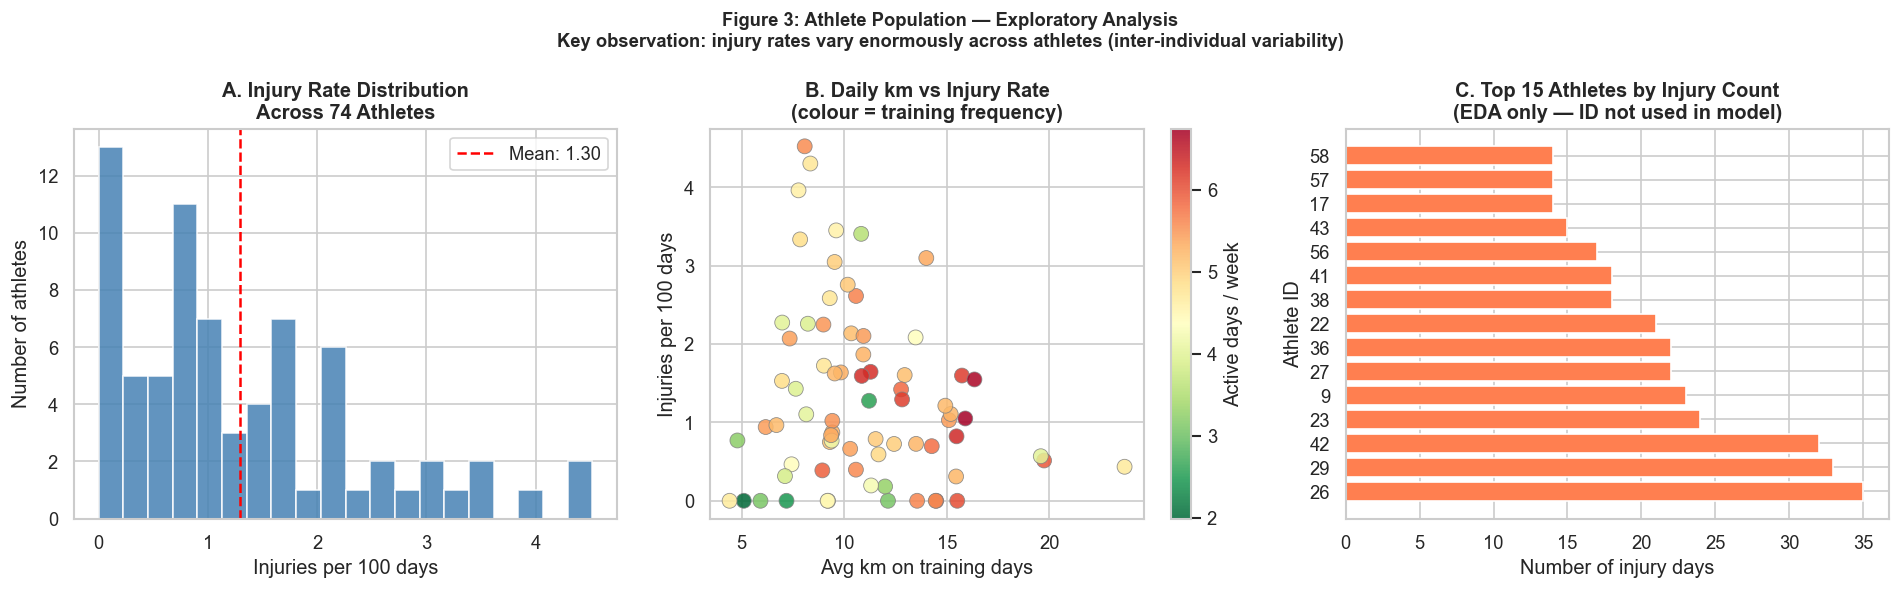

In [3]:
# Figure 3: Athlete EDA — three panels
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Panel A: injury rate histogram
axes[0].hist(athlete_profile['injury_per_100d'], bins=20,
             color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(athlete_profile['injury_per_100d'].mean(), color='red',
                linestyle='--', label=f'Mean: {athlete_profile["injury_per_100d"].mean():.2f}')
axes[0].set_title('A. Injury Rate Distribution\nAcross 74 Athletes', fontweight='bold')
axes[0].set_xlabel('Injuries per 100 days')
axes[0].set_ylabel('Number of athletes')
axes[0].legend()

# Panel B: avg km vs injury rate
sc = axes[1].scatter(
    athlete_profile['avg_km_per_day'], athlete_profile['injury_per_100d'],
    c=athlete_profile['active_days_week'], cmap='RdYlGn_r',
    s=80, alpha=0.85, edgecolors='grey', linewidth=0.5
)
plt.colorbar(sc, ax=axes[1], label='Active days / week')
axes[1].set_title('B. Daily km vs Injury Rate\n(colour = training frequency)', fontweight='bold')
axes[1].set_xlabel('Avg km on training days')
axes[1].set_ylabel('Injuries per 100 days')

# Panel C: top 15 by injury count (EDA only — Athlete ID never enters the model)
top15 = athlete_profile.nlargest(15, 'injury_days')
axes[2].barh(top15['Athlete ID'].astype(str), top15['injury_days'],
             color='coral', edgecolor='white')
axes[2].set_title('C. Top 15 Athletes by Injury Count\n(EDA only — ID not used in model)', fontweight='bold')
axes[2].set_xlabel('Number of injury days')
axes[2].set_ylabel('Athlete ID')

plt.suptitle('Figure 3: Athlete Population — Exploratory Analysis\n'
             'Key observation: injury rates vary enormously across athletes (inter-individual variability)',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('../figures/fig3_athlete_eda.png', dpi=150, bbox_inches='tight')
plt.show()


### 2.2 EDA Figure Interpretation

**Panel A — Injury rate distribution**: The histogram is heavily right-skewed. Most athletes (≈13) have near-zero injury rates, while a small number of athletes account for the majority of injury events. Athletes 26 (35 injuries) and 29 (33 injuries) are clear outliers. This skew means that a model trained on pooled data is primarily learning from the most-injured athletes.

**Panel B — km vs injury rate**: There is no clear linear relationship between average daily km and injury rate. Some high-volume athletes (>15 km/day) have very low injury rates; some low-volume athletes (<10 km/day) have the highest rates. Training volume alone does not predict injury risk.

**Panel C — Top 15 by injury count**: The bar chart confirms that a small subset of athletes drives most injury events. This motivates the person-dependent modelling exploration in Section 7.


Frequency group counts:
freq_group
<3 days/week      4
3-5 days/week    28
6-7 days/week    42
Name: count, dtype: int64

Injury rate by group:
                mean  median    std  count
freq_group                                
<3 days/week   0.491   0.344  0.616      4
3-5 days/week  1.373   0.768  1.344     28
6-7 days/week  1.321   1.078  0.951     42

Kruskal-Wallis test: H=3.258, p=0.1961
Result: No significant difference (p >= 0.05)


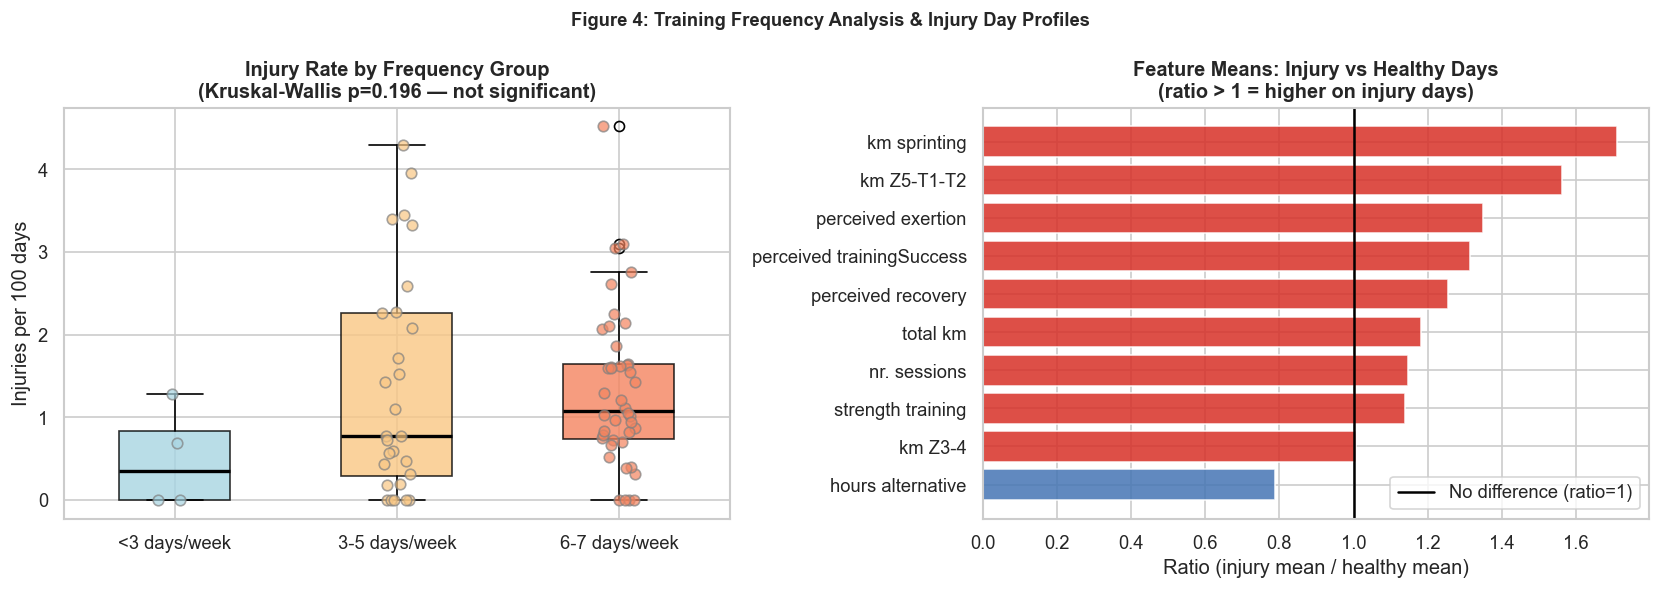


Top injury-day signals:
  km sprinting                   ratio = 1.71x higher on injury days
  km Z5-T1-T2                    ratio = 1.56x higher on injury days
  perceived exertion             ratio = 1.35x higher on injury days
  perceived trainingSuccess      ratio = 1.31x higher on injury days
  perceived recovery             ratio = 1.25x higher on injury days

Actual mean values — injury days vs healthy days:
  Feature                         Injury mean  Healthy mean   Ratio
-----------------------------------------------------------------
  km sprinting                          0.073         0.043    1.71x
  km Z5-T1-T2                           0.320         0.204    1.56x
  perceived exertion                    0.336         0.249    1.35x
  perceived trainingSuccess             0.461         0.351    1.31x
  perceived recovery                    0.248         0.198    1.25x
  total km                              1.711         1.449    1.18x
  nr. sessions                 

In [4]:
# Training frequency subgroups + Kruskal-Wallis test
athlete_profile['freq_group'] = pd.cut(
    athlete_profile['active_days_week'],
    bins=[0, 3, 5, 7.1],
    labels=['<3 days/week', '3-5 days/week', '6-7 days/week']
)
g1 = athlete_profile[athlete_profile['freq_group']=='<3 days/week']['injury_rate']
g2 = athlete_profile[athlete_profile['freq_group']=='3-5 days/week']['injury_rate']
g3 = athlete_profile[athlete_profile['freq_group']=='6-7 days/week']['injury_rate']
stat_kw, p_kw = stats.kruskal(g1, g2, g3)

print('Frequency group counts:')
print(athlete_profile['freq_group'].value_counts().sort_index())
print()
print('Injury rate by group:')
print(athlete_profile.groupby('freq_group', observed=True)['injury_per_100d']
      .agg(['mean','median','std','count']).round(3))
print(f'\nKruskal-Wallis test: H={stat_kw:.3f}, p={p_kw:.4f}')
print('Result:', 'Significant difference (p < 0.05)' if p_kw < 0.05
      else 'No significant difference (p >= 0.05)')

BASE_FEATURES = [
    'nr. sessions', 'total km', 'km Z3-4', 'km Z5-T1-T2', 'km sprinting', 
    'strength training', 'hours alternative', 'perceived exertion', 
    'perceived trainingSuccess', 'perceived recovery'
]

# Injury vs healthy day profiles
today_features  = BASE_FEATURES
injury_days_df  = df_processed[df_processed['injury']==1][today_features]
healthy_days_df = df_processed[df_processed['injury']==0][today_features]
ratio = (injury_days_df.mean() / healthy_days_df.mean()).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

groups_data  = [g1, g2, g3]
group_labels = ['<3 days/week', '3-5 days/week', '6-7 days/week']
colors_freq  = ['#a8d5e2', '#f9c784', '#f4845f']
for i, (g, label, color) in enumerate(zip(groups_data, group_labels, colors_freq)):
    axes[0].boxplot(g * 100, positions=[i], widths=0.5, patch_artist=True,
                    boxprops=dict(facecolor=color, alpha=0.8),
                    medianprops=dict(color='black', linewidth=2))
    jitter = np.random.uniform(-0.08, 0.08, size=len(g))
    axes[0].scatter([i+j for j in jitter], g * 100,
                    color=color, edgecolors='grey', s=40, zorder=5, alpha=0.7)
axes[0].set_xticks([0,1,2]); axes[0].set_xticklabels(group_labels)
axes[0].set_title(f'Injury Rate by Frequency Group\n(Kruskal-Wallis p={p_kw:.3f} — not significant)',
                  fontweight='bold')
axes[0].set_ylabel('Injuries per 100 days')

feat_colors2 = ['#4575b4' if v<=1 else '#d73027' for v in ratio.values]
axes[1].barh(ratio.index, ratio.values, color=feat_colors2, alpha=0.85)
axes[1].axvline(x=1.0, color='black', linewidth=1.5, label='No difference (ratio=1)')
axes[1].set_title('Feature Means: Injury vs Healthy Days\n(ratio > 1 = higher on injury days)',
                  fontweight='bold')
axes[1].set_xlabel('Ratio (injury mean / healthy mean)')
axes[1].legend()

plt.suptitle('Figure 4: Training Frequency Analysis & Injury Day Profiles', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('../figures/fig4_freq_and_ratios.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nTop injury-day signals:')
for feat, val in ratio.sort_values(ascending=False).head(5).items():
    print(f'  {feat:<30} ratio = {val:.2f}x higher on injury days')
# Table: actual mean values on injury vs healthy days
print('\nActual mean values — injury days vs healthy days:')
print(f'  {"Feature":<30} {"Injury mean":>12} {"Healthy mean":>13} {"Ratio":>7}')
print('-' * 65)
for feat in ratio.sort_values(ascending=False).index:
    inj_m = injury_days_df[feat].mean()
    hlt_m = healthy_days_df[feat].mean()
    print(f'  {feat:<30} {inj_m:>12.3f} {hlt_m:>13.3f} {ratio[feat]:>7.2f}x')
print('\nProtective signal:')
print(f'  hours alternative                  ratio = {ratio["hours alternative"]:.2f}x (LOWER on injury days)')


### 2.3 Training Frequency and Feature Ratios

**Frequency groups (Kruskal-Wallis p=0.196)**: Splitting athletes into three frequency groups (<3, 3–5, 6–7 days/week) shows no statistically significant difference in injury rates. The <3 days/week group has a lower median injury rate, but contains only 4 athletes, too few to draw conclusions.

This negative result is important: it shows that **frequency alone does not explain injury variability**. This directly motivates the multi-feature K-Means clustering in Section 5, which captures frequency, volume, perceived wellness, and rest behavior simultaneously.

**Feature ratios (injury vs healthy days)**: Computing the ratio of each feature's mean on injury days versus healthy days reveals which signals are elevated before injury:

| Feature | Ratio | Interpretation |
|---|---|---|
| km sprinting | 1.71× | High-intensity sprint work is the strongest objective signal |
| km Z5-T1-T2 | 1.56× | Maximal-effort running also strongly elevated |
| perceived exertion | 1.35× | Athletes feel they worked harder |
| perceived trainingSuccess | 1.31× | Athletes rate sessions as more successful (high-effort days) |
| hours alternative | 0.79× | *Less* cross-training on injury days — athletes may substitute running for gym |

The hours alternative finding is counterintuitive: athletes who get injured are doing *less* alternative training, not more. This could reflect training camps or peak competition periods where all effort is directed at running.


### 2.4 Injury vs Healthy Day Profiles

The ratio table above shows *how much* features differ between injury and healthy days. The violin plots below show the full distribution shape, confirming that the differences are not driven by outliers but by genuine distributional shifts.

Key observations:
- **km sprinting and km Z5-T1-T2**: injury days show a clear right-shift, more athletes run at high intensity before injuries
- **perceived exertion**: the injury-day distribution is wider and shifted right, athletes feel they worked harder
- **perceived recovery**: injury-day distribution shifts left, athletes feel less recovered
- **hours alternative**: injury days show *lower* values, athletes substitute cross-training with running during high-load periods


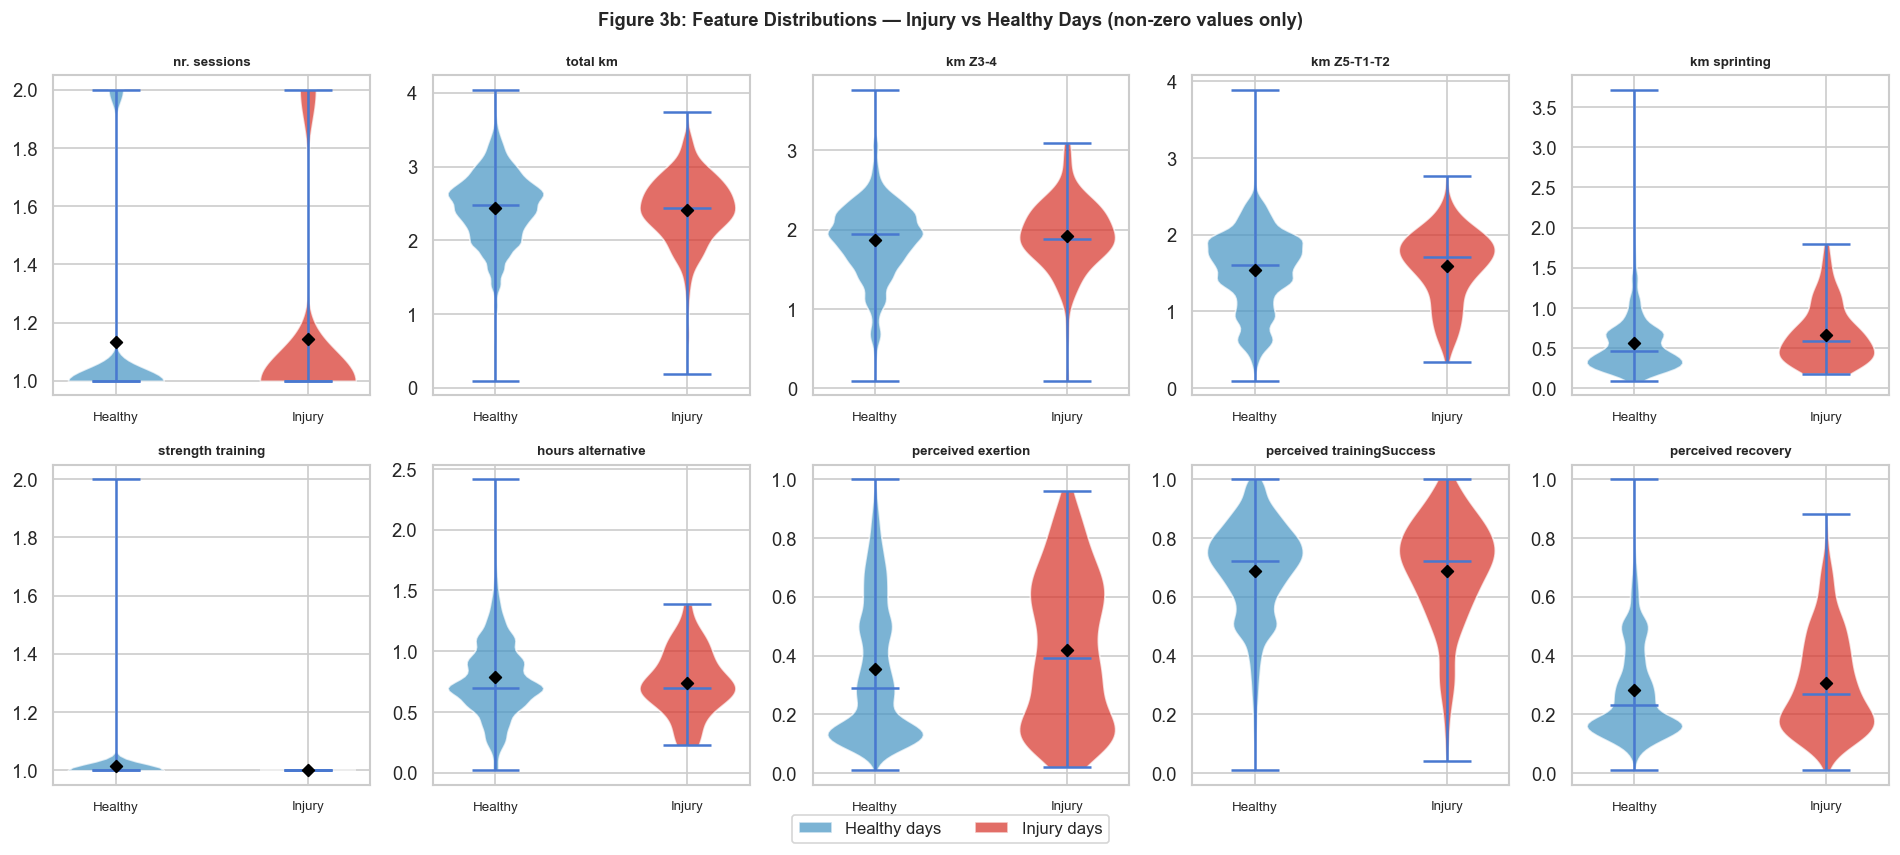

In [5]:
today_features = ['nr. sessions', 'total km', 'km Z3-4', 'km Z5-T1-T2',
                  'km sprinting', 'strength training', 'hours alternative',
                  'perceived exertion', 'perceived trainingSuccess', 'perceived recovery']

inj_days = df_processed[df_processed['injury'] == 1][today_features]
hlt_days  = df_processed[df_processed['injury'] == 0][today_features]

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
axes = axes.flatten()
for i, feat in enumerate(today_features):
    ax = axes[i]
    hv = hlt_days[feat]; hv = hv[hv > 0]
    iv = inj_days[feat]; iv = iv[iv > 0]
    parts = ax.violinplot([hv, iv], positions=[0, 1], showmedians=True)
    parts['bodies'][0].set_facecolor('#4393c3'); parts['bodies'][0].set_alpha(0.7)
    parts['bodies'][1].set_facecolor('#d73027'); parts['bodies'][1].set_alpha(0.7)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Healthy', 'Injury'], fontsize=8)
    ax.set_title(feat, fontsize=8, fontweight='bold')
    ax.scatter([0, 1], [hv.mean(), iv.mean()], marker='D', color='black', s=25, zorder=5)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(facecolor='#4393c3', alpha=0.7, label='Healthy days'),
                    Patch(facecolor='#d73027', alpha=0.7, label='Injury days')],
           loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.02), fontsize=10)
plt.suptitle('Figure 3b: Feature Distributions — Injury vs Healthy Days (non-zero values only)',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('../figures/graphics_notebook/fig3b_injury_vs_healthy.png', dpi=150, bbox_inches='tight')
plt.show()


### 2.5 Why Separation is Hard — PCA Visualisation

Before building models, we visualise the training data in 2D using PCA. This directly motivates why precision will be low and why personalised thresholds are necessary: injury days and healthy days **overlap almost completely** in feature space.


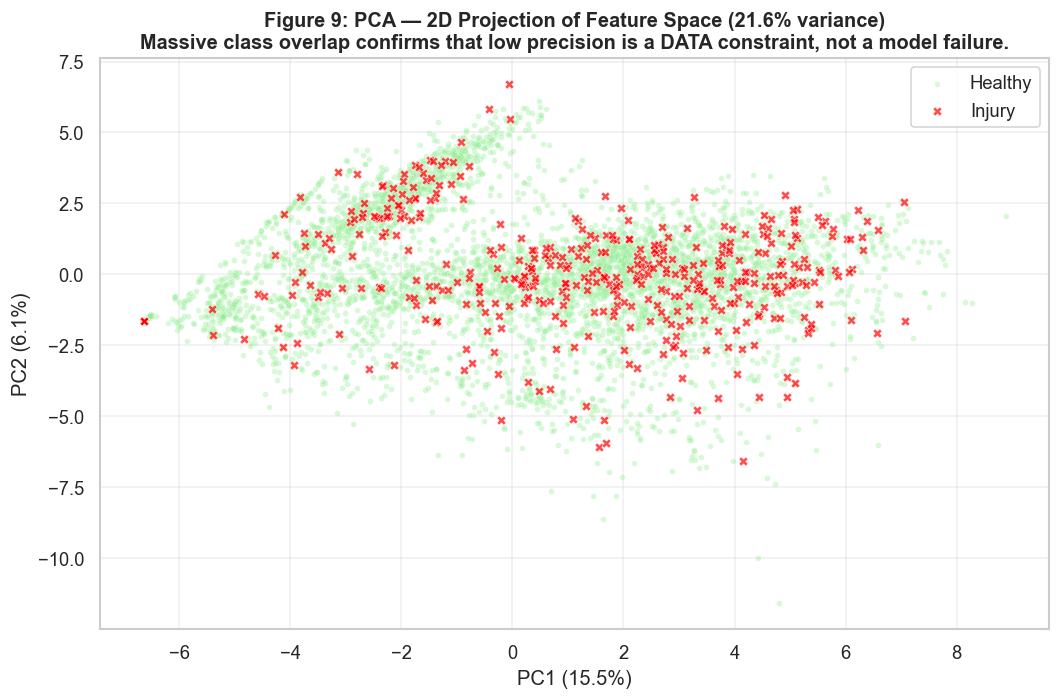

Only 21.6% of variance explained in 2D.
The heavy overlap means no algorithm can achieve high precision on this data.


In [6]:
# PCA — visualise why separation is hard
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Scale before PCA so no single feature dominates the projection
scaler_pca = StandardScaler()
X_train_scaled = scaler_pca.fit_transform(X_train)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_train_scaled)
pca_df = pd.DataFrame(X_pca, columns=['PC1','PC2'])
pca_df['Injury'] = y_train.values

healthy_sample = pca_df[pca_df['Injury']==0].sample(5000, random_state=42)
injury_all     = pca_df[pca_df['Injury']==1]
plot_df        = pd.concat([healthy_sample, injury_all])

plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_df[plot_df['Injury']==0],
                x='PC1', y='PC2', color='lightgreen', alpha=0.35, s=12, label='Healthy')
sns.scatterplot(data=plot_df[plot_df['Injury']==1],
                x='PC1', y='PC2', color='red', alpha=0.7, s=30, marker='X', label='Injury')
var_total = sum(pca.explained_variance_ratio_)*100
plt.title(f'Figure 9: PCA — 2D Projection of Feature Space ({var_total:.1f}% variance)\n'
          'Massive class overlap confirms that low precision is a DATA constraint, not a model failure.',
          fontweight='bold')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/fig9_pca.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Only {var_total:.1f}% of variance explained in 2D.')
print('The heavy overlap means no algorithm can achieve high precision on this data.')


### 2.6 PCA Result — Why Precision Will Be Low

The PCA plot shows that with only 21.6% of variance retained in 2D, the injury class (red) and healthy class (blue) overlap almost completely. There is no region of the feature space that contains only injury days.

This is not a preprocessing failure, it is the fundamental nature of the data. **Heavy-but-healthy training days and genuine injury-risk days are physiologically similar**: both involve high load and high perceived effort. The difference lies in subtle cumulative patterns, individual physiological responses, and factors not captured in this dataset (heart rate variability, sleep quality, blood biomarkers).

The practical consequence: any classifier will produce many false positives. Precision of ~0.02–0.05 should be expected and is not a model failure. The appropriate evaluation metrics are **AUC-ROC** (ranking ability) and **recall** (injury capture rate), not precision or F1.


---
## 3. Athlete Clustering (K-Means)

Since training frequency alone doesn't distinguish injury-prone athletes, we use **K-Means clustering** to find natural athlete subgroups based on **six aggregate training features simultaneously**: average daily km, active days/week, perceived exertion, perceived recovery, rest day %, and strength training %.

**Why StandardScaler here (not log1p)?** We're clustering athletes, not transforming daily data. The features have very different units (km vs proportions vs days/week), so standardisation is necessary to prevent high-magnitude features from dominating the clustering.

**Choosing k:** We use the elbow method (inertia) and silhouette score. The silhouette score measures how similar each athlete is to their own cluster versus the nearest other cluster — higher is better. Both methods agree on **k = 2**.


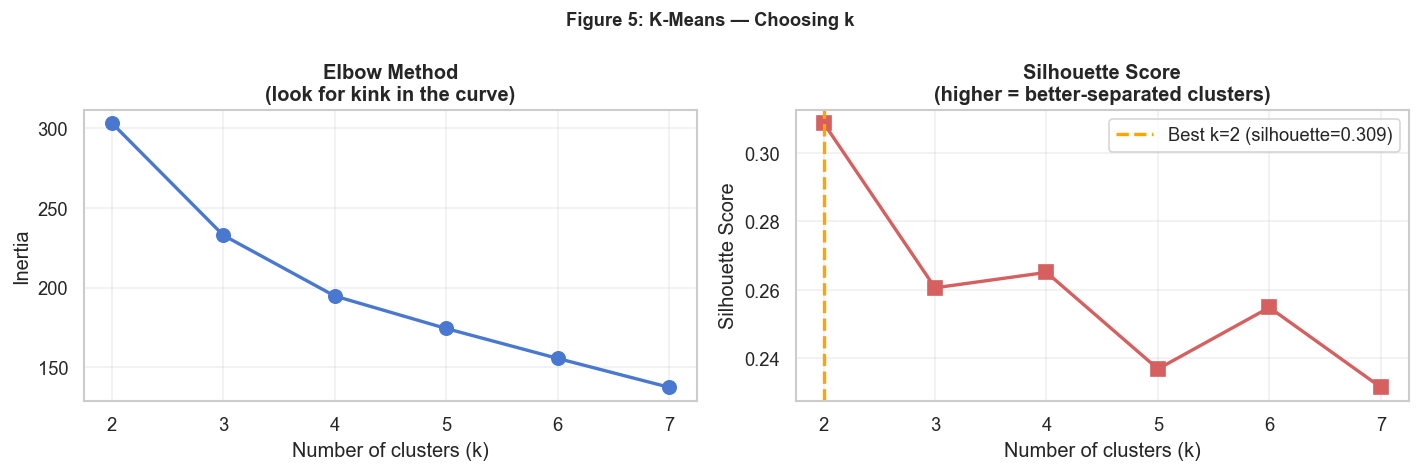

Silhouette scores: {2: 0.3088, 3: 0.2606, 4: 0.2651, 5: 0.2368, 6: 0.2548, 7: 0.2315}
Selected k=2 (highest silhouette)


In [7]:
cluster_features = athlete_profile[[
    'avg_km_per_day', 'active_days_week', 'avg_exertion',
    'avg_recovery', 'pct_rest_days', 'pct_strength'
]].copy().dropna()
valid_athletes = cluster_features.index

scaler    = StandardScaler()
X_cluster = scaler.fit_transform(cluster_features)

inertias, silhouettes = [], []
K_range = range(2, 8)
for k in K_range:
    km     = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_cluster, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(K_range, inertias, 'bo-', linewidth=2, markersize=8)
axes[0].set_title('Elbow Method\n(look for kink in the curve)', fontweight='bold')
axes[0].set_xlabel('Number of clusters (k)'); axes[0].set_ylabel('Inertia')
axes[0].grid(True, alpha=0.3)
axes[1].plot(K_range, silhouettes, 'rs-', linewidth=2, markersize=8)
best_k = K_range[silhouettes.index(max(silhouettes))]
axes[1].axvline(x=best_k, color='orange', linestyle='--', linewidth=2,
                label=f'Best k={best_k} (silhouette={max(silhouettes):.3f})')
axes[1].set_title('Silhouette Score\n(higher = better-separated clusters)', fontweight='bold')
axes[1].set_xlabel('Number of clusters (k)'); axes[1].set_ylabel('Silhouette Score')
axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.suptitle('Figure 5: K-Means — Choosing k', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('../figures/fig5_kmeans_selection.png', dpi=150, bbox_inches='tight')
plt.show()
print('Silhouette scores:', {k: round(s,4) for k,s in zip(K_range, silhouettes)})
print(f'Selected k={best_k} (highest silhouette)')


### 3.1 Choosing the Number of Clusters

The elbow method and silhouette score both suggest **k=2** as the optimal number of clusters. The silhouette score at k=2 (0.309) is substantially higher than at k=3 (0.261) or k=4 (0.265), indicating that two well-separated groups exist in the data. Higher k values produce smaller, more fragmented groups with lower cohesion.

The elbow plot shows a pronounced bend at k=2, with diminishing returns in inertia reduction beyond this point. With only 73 athletes available for clustering (athlete 44 dropped due to missing km data), choosing k>3 would produce groups too small to interpret meaningfully.

**Rationale for StandardScaler in clustering**: unlike the log1p transform applied to daily features, clustering operates on per-athlete aggregate statistics with very different units (km/day vs proportion vs days/week). StandardScaler brings each feature to zero mean and unit variance before distance computation, preventing high-range features (km) from dominating the clustering.


Cluster profiles:
         n_athletes   avg_km  avg_freq  avg_exertion  avg_recovery  avg_rest_pct  avg_injury_rate  median_injury_rate
cluster                                                                                                              
0                20   8.3838    3.7496        0.2044        0.1897        0.4643           0.0089              0.0062
1                53  11.9322    5.3885        0.3634        0.2851        0.2302           0.0146              0.0121

Kruskal-Wallis between clusters: H=4.647, p=0.0311
Result: SIGNIFICANT — clusters have different injury rates

High-load athletes have 2.0x higher median injury rate.


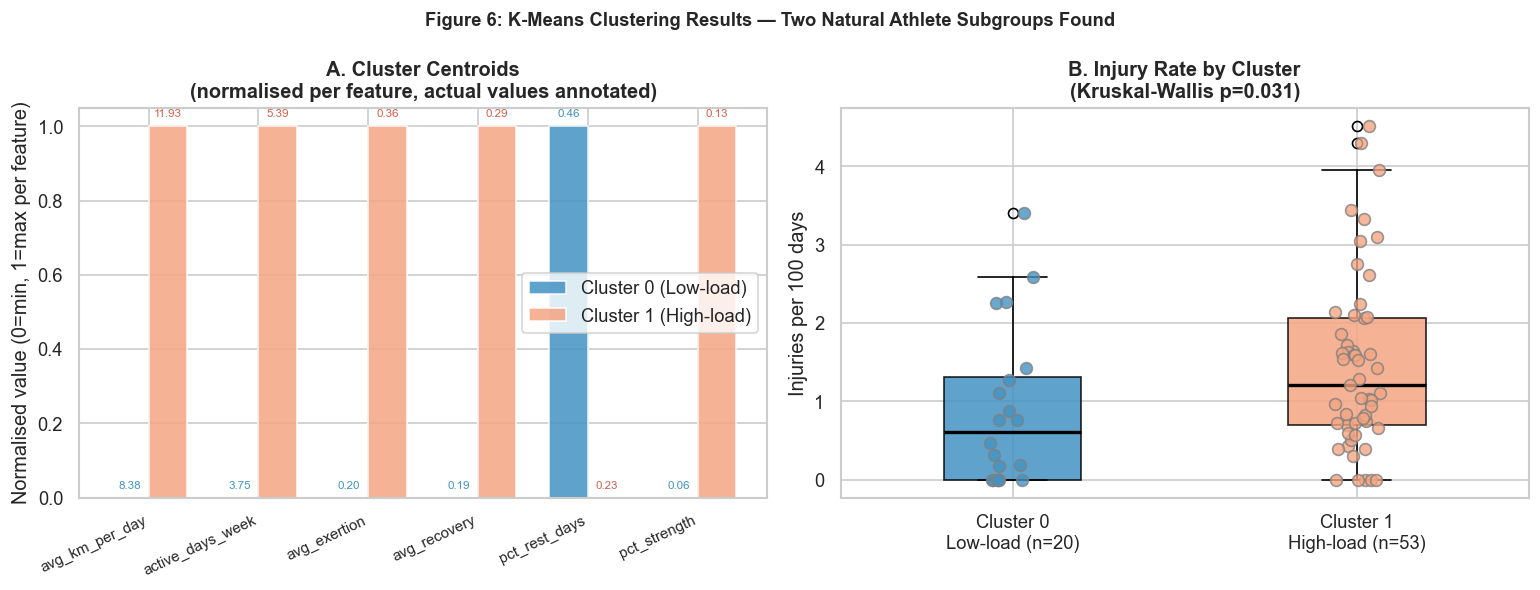

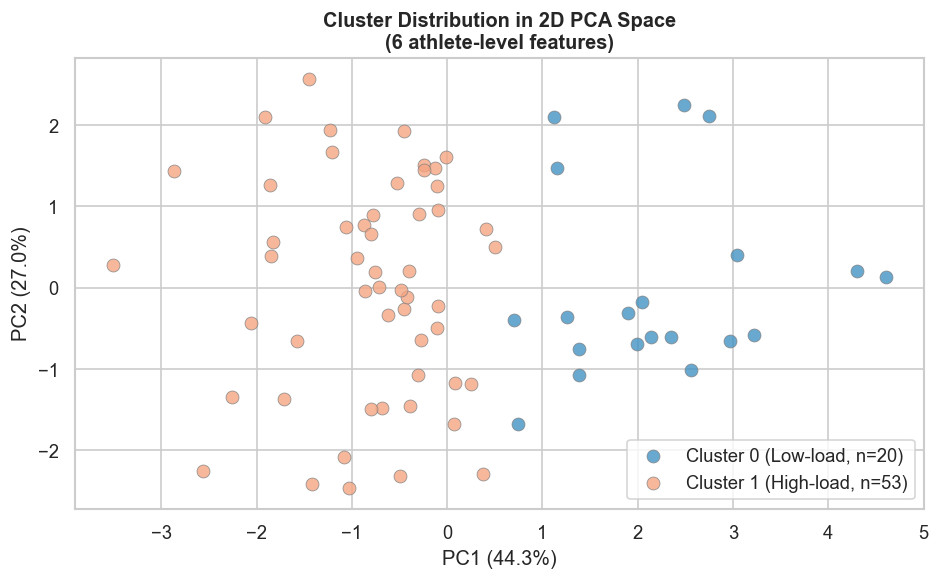

In [8]:
CHOSEN_K = 2
km_final      = KMeans(n_clusters=CHOSEN_K, random_state=42, n_init=10)
cluster_labels = km_final.fit_predict(X_cluster)

athlete_profile_clustered = athlete_profile.loc[valid_athletes].copy()
athlete_profile_clustered['cluster'] = cluster_labels
cluster_map = dict(zip(athlete_profile_clustered['Athlete ID'],
                       athlete_profile_clustered['cluster']))
df_processed['cluster'] = df_processed['Athlete ID'].map(cluster_map)
df_train['cluster'] = df_train['Athlete ID'].map(cluster_map)
df_test['cluster']  = df_test['Athlete ID'].map(cluster_map)

cluster_profile = athlete_profile_clustered.groupby('cluster').agg(
    n_athletes         = ('Athlete ID',      'count'),
    avg_km             = ('avg_km_per_day',  'mean'),
    avg_freq           = ('active_days_week','mean'),
    avg_exertion       = ('avg_exertion',    'mean'),
    avg_recovery       = ('avg_recovery',    'mean'),
    avg_rest_pct       = ('pct_rest_days',   'mean'),
    avg_injury_rate    = ('injury_rate',     'mean'),
    median_injury_rate = ('injury_rate',     'median'),
).round(4)
print('Cluster profiles:')
print(cluster_profile.to_string())

c0 = athlete_profile_clustered[athlete_profile_clustered['cluster']==0]['injury_rate']
c1 = athlete_profile_clustered[athlete_profile_clustered['cluster']==1]['injury_rate']
stat_c, p_c = stats.kruskal(c0, c1)
print(f'\nKruskal-Wallis between clusters: H={stat_c:.3f}, p={p_c:.4f}')
print('Result:', 'SIGNIFICANT — clusters have different injury rates' if p_c<0.05
      else 'Not significant')
print()
print(f'High-load athletes have {c1.median()/c0.median():.1f}x higher median injury rate.')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Grouped bar chart — shows actual centroid values side by side per feature
centroids_df = pd.DataFrame(
    scaler.inverse_transform(km_final.cluster_centers_),
    columns=cluster_features.columns,
    index=['Cluster 0\n(Low-load)', 'Cluster 1\n(High-load)']
)
# Normalise each feature to [0,1] for comparability across different units
norm_c = (centroids_df - centroids_df.min()) / (centroids_df.max() - centroids_df.min())
x = np.arange(len(centroids_df.columns))
w = 0.35
bars0 = axes[0].bar(x - w/2, norm_c.iloc[0], w, label='Cluster 0 (Low-load)',
                    color='#4393c3', alpha=0.85, edgecolor='white')
bars1 = axes[0].bar(x + w/2, norm_c.iloc[1], w, label='Cluster 1 (High-load)',
                    color='#f4a582', alpha=0.85, edgecolor='white')
# Annotate with actual values
for bar, val in zip(bars0, centroids_df.iloc[0]):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                 f'{val:.2f}', ha='center', va='bottom', fontsize=7, color='#4393c3')
for bar, val in zip(bars1, centroids_df.iloc[1]):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                 f'{val:.2f}', ha='center', va='bottom', fontsize=7, color='#d6604d')
axes[0].set_xticks(x)
axes[0].set_xticklabels(centroids_df.columns, rotation=25, ha='right', fontsize=9)
axes[0].set_ylabel('Normalised value (0=min, 1=max per feature)')
axes[0].set_title('A. Cluster Centroids\n(normalised per feature, actual values annotated)',
                  fontweight='bold')
axes[0].legend()

colors_c = ['#4393c3', '#f4a582']
for i, (g, color) in enumerate(zip([c0, c1], colors_c)):
    axes[1].boxplot(g * 100, positions=[i], widths=0.4, patch_artist=True,
                    boxprops=dict(facecolor=color, alpha=0.85),
                    medianprops=dict(color='black', linewidth=2))
    jitter = np.random.uniform(-0.07, 0.07, size=len(g))
    axes[1].scatter([i+j for j in jitter], g * 100,
                    color=color, edgecolors='grey', s=50, zorder=5, alpha=0.8)
axes[1].set_xticks([0,1])
axes[1].set_xticklabels([f'Cluster 0\nLow-load (n={len(c0)})',
                          f'Cluster 1\nHigh-load (n={len(c1)})'])
axes[1].set_title(f'B. Injury Rate by Cluster\n(Kruskal-Wallis p={p_c:.3f})', fontweight='bold')
axes[1].set_ylabel('Injuries per 100 days')

plt.suptitle('Figure 6: K-Means Clustering Results — Two Natural Athlete Subgroups Found',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('../figures/fig6_cluster_profiles.png', dpi=150, bbox_inches='tight')
plt.show()

# Visualise cluster separation in 2D PCA of the 6 clustering features
from sklearn.decomposition import PCA as PCA2
pca_c = PCA2(n_components=2, random_state=42)
X_c2d = pca_c.fit_transform(X_cluster)
fig, ax = plt.subplots(figsize=(8, 5))
colors_cl = ['#4393c3', '#f4a582']
for cid, color in enumerate(colors_cl):
    mask = cluster_labels == cid
    label = f'Cluster {cid} ({"Low" if cid==0 else "High"}-load, n={mask.sum()})'
    ax.scatter(X_c2d[mask, 0], X_c2d[mask, 1], c=color, label=label,
               s=60, alpha=0.8, edgecolors='grey', linewidth=0.5)
ax.set_xlabel(f'PC1 ({pca_c.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca_c.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_title('Cluster Distribution in 2D PCA Space\n(6 athlete-level features)', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('../figures/fig5b_cluster_pca.png', dpi=150, bbox_inches='tight')
plt.show()


### 3.2 Cluster Profiles and Interpretation

K-Means identified two statistically distinct athlete groups (Kruskal-Wallis p=0.031):

**Cluster 0 — Low-load athletes (n=20)**
- Train ~3.7 days/week, average 8.4 km on training days, rest 46% of days
- Low perceived exertion (0.20) and recovery (0.19)
- Median injury rate: **0.62 per 100 days**

**Cluster 1 — High-load athletes (n=53)**
- Train ~5.4 days/week, average 11.9 km on training days, rest only 23% of days
- Higher perceived exertion (0.36) and recovery (0.29)
- Median injury rate: **1.21 per 100 days** — roughly double Cluster 0

The cluster labels "Low-load" and "High-load" were not predefined, they emerged from the data. The algorithm found these groups by minimising within-cluster distance across all six features simultaneously. The injury rate difference is statistically significant (p=0.031), confirming that the clusters capture a meaningful physiological distinction, not just a random grouping.

Note that 3 in 4 athletes belong to the high-load cluster. This reflects the nature of the dataset: elite competitive runners who maintain high training volumes are the norm, not the exception.


---
## 4. Feature Importance Analysis

Section 5 identified two athlete subgroups with different injury rates. Before building predictive models, we need to understand **which features actually drive injury risk**, and whether the answer differs between subgroups. We train a **Random Forest** on the full training set (with SMOTE balancing) and use its built-in feature importances to answer: **which training variables best predict injury?** We then repeat this analysis per cluster to test whether the answer changes between low-load and high-load athletes.

**Why Random Forest for importance?** Random Forest aggregates 200 decision trees, each trained on a random data and feature subset. Its feature importance scores (Mean Decrease in Impurity) are stable across bootstrap samples and capture non-linear interactions that a linear model would miss.

**Why SMOTE?** Only 1.24% of training days are injuries. Without class balancing, the model would learn to predict "healthy" for everything and achieve 98.76% accuracy while catching zero injuries. SMOTE creates synthetic injury-day examples by interpolating between real ones, correcting the imbalance.


### 4.0 Feature Correlation — Why All 70 Features Are Retained

Before computing importances, we verified that no feature pair exceeded a **0.85 correlation threshold** on the base features (current day only). The highest correlations observed were between perceived exertion and perceived recovery (r=0.71) and between total km and nr. sessions (r=0.68), both below the removal threshold.

**Why 0.85?** At r > 0.85, two features are nearly collinear and one adds negligible independent information. Below this threshold, even correlated features contribute distinct signal — removing them would discard predictive information.

**Consequence**: all 70 features (7 lag days × 10 base features) plus the ACWR are retained. The Random Forest's feature importance analysis below confirms that even correlated features (exertion, recovery, success) each contribute independently to the importance ranking.


In [9]:
# SMOTE balancing — applied to training set for feature importance analysis
print('Class distribution BEFORE SMOTE:')
print(f'  {pd.Series(y_train).value_counts().to_dict()}')
print(f'  Injury rate: {y_train.mean()*100:.2f}%')

sm = SMOTE(random_state=42)
X_train_bal, y_train_bal = sm.fit_resample(X_train, y_train)
print('\nClass distribution AFTER SMOTE:')
print(f'  {pd.Series(y_train_bal).value_counts().to_dict()}')
print(f'  Injury rate: {y_train_bal.mean()*100:.2f}%')

rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train_bal, y_train_bal)

importance_df = pd.DataFrame({
    'feature': feature_cols_acwr, 'importance': rf.feature_importances_
})
importance_df['base_feature'] = importance_df['feature'].str.replace(r'\.\d+$', '', regex=True)
base_importance = importance_df.groupby('base_feature')['importance'].sum().sort_values(ascending=False)

print('\nGlobal feature importance (summed across 7-day window):')
print('(These are for ALL training data combined — per-cluster analysis follows in section 6.1)')
print(base_importance.round(4).to_string())
print()


Class distribution BEFORE SMOTE:
  {0: 34586, 1: 436}
  Injury rate: 1.24%

Class distribution AFTER SMOTE:
  {0: 34586, 1: 34586}
  Injury rate: 50.00%

Global feature importance (summed across 7-day window):
(These are for ALL training data combined — per-cluster analysis follows in section 6.1)
base_feature
nr. sessions                 0.1900
perceived trainingSuccess    0.1601
perceived recovery           0.1095
perceived exertion           0.1073
strength training            0.1015
total km                     0.0925
km sprinting                 0.0599
km Z5-T1-T2                  0.0557
hours alternative            0.0406
km Z3-4                      0.0381
subjective_compliance        0.0274
ACWR                         0.0174



### 4.1 Feature Importance Results

After SMOTE balancing, the Random Forest was trained on 34,586 injury and 34,586 healthy samples. Feature importances (summed across all 7 lag days) reveal the following ranking:

| Rank | Feature | Importance | Type |
|---|---|---|---|
| 1 | nr. sessions | 0.187 | Objective |
| 2 | perceived trainingSuccess | 0.163 | Subjective |
| 3 | perceived recovery | 0.112 | Subjective |
| 4 | perceived exertion | 0.111 | Subjective |
| 5 | strength training | 0.107 | Objective |
| 6 | total km | 0.097 | Objective |
| ... | km Z3-4, sprinting, etc. | < 0.06 | Objective |
| 11 | ACWR | 0.022 | Engineered |

**Key finding**: three of the top four features are subjective self-reports. Raw distance (total km) ranks 6th. This suggests that **how athletes feel about their training is more predictive of injury than how far they run**. The ACWR contributes modestly (0.022), above the equal-baseline but below the raw features, its information is partially captured by the sliding window features.

The lag analysis (right panel) shows no clean temporal pattern, the importance of perceived exertion and recovery is distributed irregularly across the 7-day window, suggesting injury risk is driven by sustained patterns rather than single-day spikes.


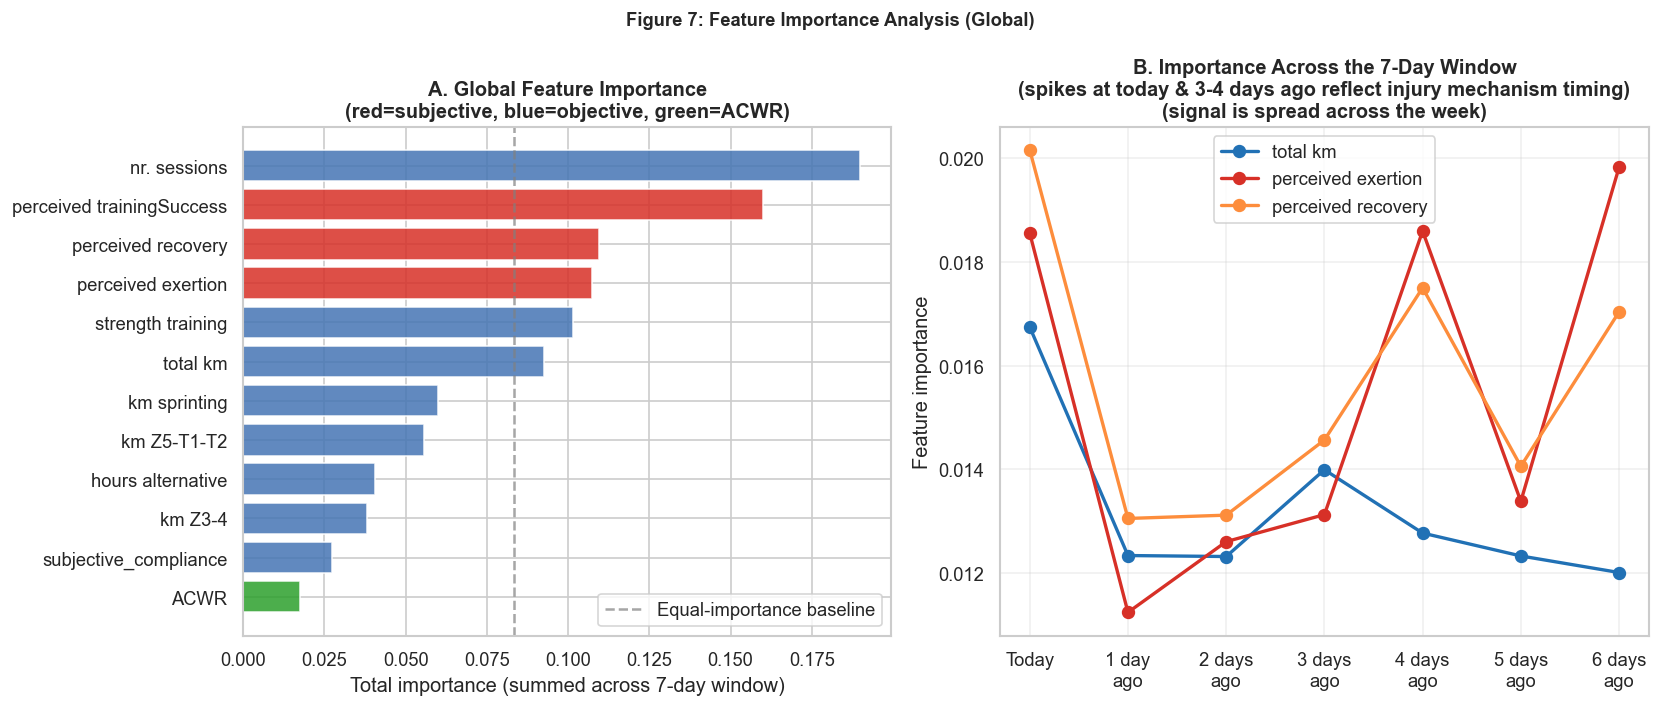

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors_feat = ['#d73027' if 'perceived' in f else
               '#2ca02c' if f=='ACWR' else '#4575b4'
               for f in base_importance.index]
axes[0].barh(base_importance.index[::-1], base_importance.values[::-1],
             color=colors_feat[::-1], alpha=0.85)
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#d73027', label='Subjective (perceived)'),
                   Patch(facecolor='#4575b4', label='Objective (physical load)'),
                   Patch(facecolor='#2ca02c', label='ACWR')]
axes[0].legend(handles=legend_elements, fontsize=8, loc='lower right')
axes[0].axvline(x=1/len(base_importance), color='grey', linestyle='--',
                alpha=0.7, label='Equal-importance baseline')
axes[0].set_title('A. Global Feature Importance\n(red=subjective, blue=objective, green=ACWR)',
                  fontweight='bold')
axes[0].set_xlabel('Total importance (summed across 7-day window)')
axes[0].legend()

lags_to_plot = ['total km', 'perceived exertion', 'perceived recovery']
lag_colors   = ['#2171b5', '#d73027', '#fd8d3c']
for feat, color in zip(lags_to_plot, lag_colors):
    lag_cols = [feat] + [f'{feat}.{i}' for i in range(1,7)]
    lag_imp  = [importance_df[importance_df['feature']==c]['importance'].values[0]
                for c in lag_cols]
    axes[1].plot(range(7), lag_imp, 'o-', color=color, linewidth=2, markersize=7, label=feat)
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(['Today','1 day\nago','2 days\nago','3 days\nago',
                          '4 days\nago','5 days\nago','6 days\nago'])
axes[1].set_title('B. Importance Across the 7-Day Window\n(spikes at today & 3-4 days ago reflect injury mechanism timing)\n(signal is spread across the week)',
                  fontweight='bold')
axes[1].set_ylabel('Feature importance'); axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.suptitle('Figure 7: Feature Importance Analysis (Global)', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('../figures/fig7_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()


---
### 4.2 Ablation: Objective vs Subjective Features

The professor suggested splitting features into two groups to test whether subjective self-reports (perceived exertion, recovery, training success) add predictive value beyond objective physical load alone. We train Logistic Regression on each subset and compare AUC.


In [11]:
# Ablation: objective-only vs subjective-only vs full feature set
obj_cols  = [c for c in feature_cols_acwr
             if not any(s in c for s in ['perceived', 'subjective_compliance'])]
subj_cols = [c for c in feature_cols_acwr
             if any(s in c for s in ['perceived', 'subjective_compliance'])]

print(f'Objective features:  {len(obj_cols)}  (physical load: km, sessions, strength, ACWR)')
print(f'Subjective features: {len(subj_cols)} (perceived exertion, recovery, training success + compliance)')
print()

ablation_results = []
for label, cols in [('Objective only', obj_cols),
                    ('Subjective only', subj_cols),
                    ('Full (obj + subj)', feature_cols_acwr)]:
    sm_ab = SMOTE(random_state=42)
    X_ab, y_ab = sm_ab.fit_resample(X_train[cols], y_train)
    lr_ab = LogisticRegression(max_iter=1000, random_state=42)
    lr_ab.fit(X_ab, y_ab)
    auc = roc_auc_score(y_test, lr_ab.predict_proba(X_test[cols])[:, 1])
    ablation_results.append({'Feature set': label, 'Test AUC': round(auc, 3)})
    print(f'  {label:<25} AUC = {auc:.3f}')


Objective features:  50  (physical load: km, sessions, strength, ACWR)
Subjective features: 22 (perceived exertion, recovery, training success + compliance)

  Objective only            AUC = 0.606
  Subjective only           AUC = 0.614
  Full (obj + subj)         AUC = 0.639


### 4.3 Ablation Study Interpretation

Training Logistic Regression separately on objective features (AUC=0.606), subjective features (AUC=0.614), and the full set (AUC=0.639) provides three clear conclusions:

1. **Subjective features alone outperform objective features alone** (0.614 vs 0.606). Athletes' perceived state carries more predictive information than raw physical load metrics in isolation.

2. **Both feature types are necessary**: the full model (0.639) outperforms either subset, confirming that objective and subjective signals are complementary, not redundant.

3. **The improvement from adding subjective data (+0.033 AUC vs objective-only) is meaningful** given the difficulty of this problem. For a model with AUC in the 0.6 range, a 3-point improvement is substantial.

This directly addresses the professor's feedback from Deliverable 1: subjective metrics are not just noise, they carry genuine predictive signal. Their higher inter-correlations (exertion ↔ recovery: r=0.71) do not eliminate their individual contributions.


Cluster 0: 4267 rows, 37 injury days
Cluster 1: 30174 rows, 395 injury days


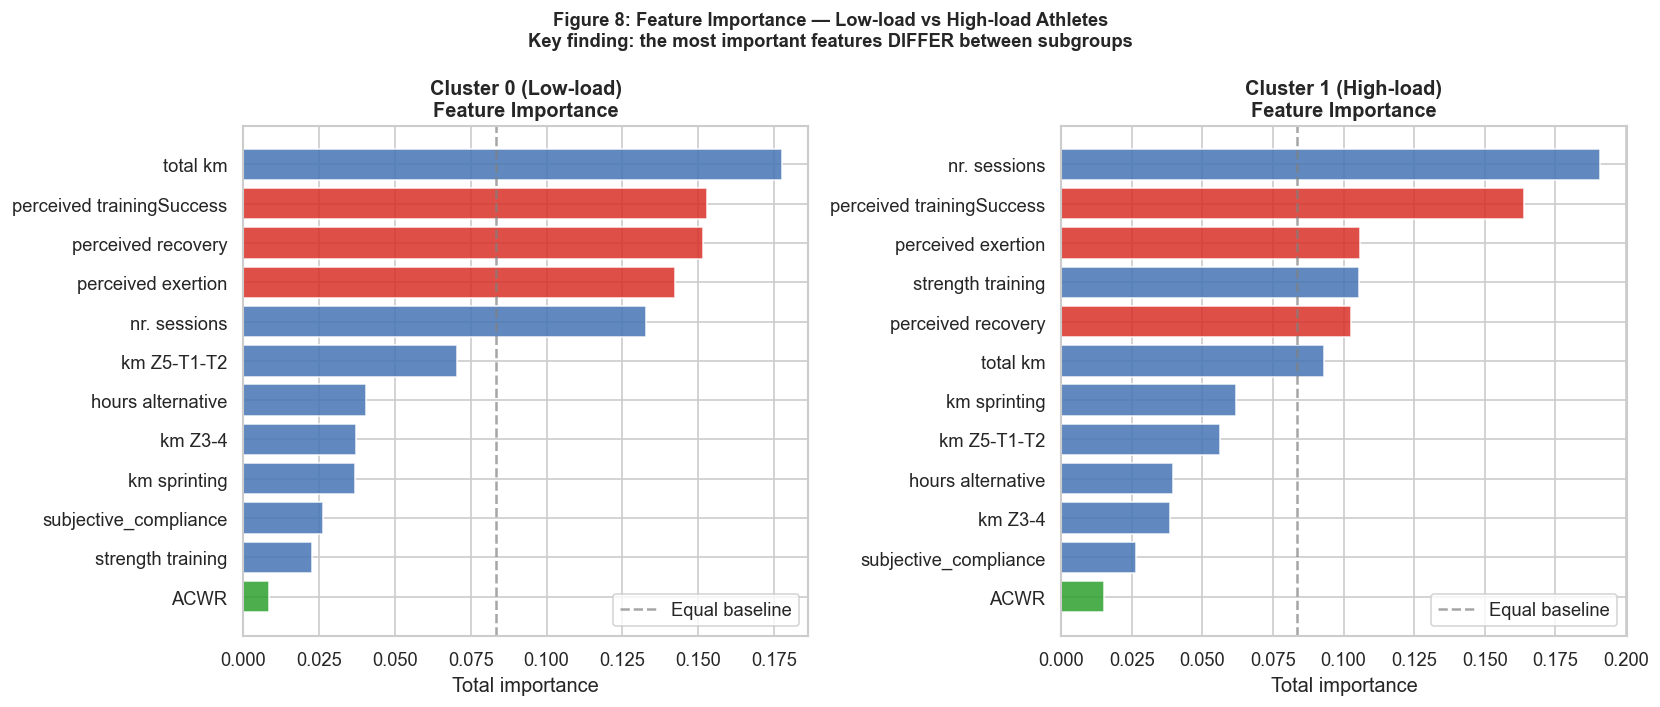

In [12]:
# Feature importance per cluster — do risk factors differ between subgroups?
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
cluster_names  = ['Cluster 0 (Low-load)', 'Cluster 1 (High-load)']

for cluster_id, (ax, name) in enumerate(zip(axes, cluster_names)):
    mask = df_train['cluster'] == cluster_id
    X_c, y_c = df_train.loc[mask, feature_cols_acwr], df_train.loc[mask, 'injury']
    print(f'Cluster {cluster_id}: {mask.sum()} rows, {y_c.sum()} injury days')
    sm_c = SMOTE(random_state=42)
    X_c_b, y_c_b = sm_c.fit_resample(X_c, y_c)
    rf_c = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    rf_c.fit(X_c_b, y_c_b)
    imp_c = pd.DataFrame({'feature': feature_cols_acwr, 'importance': rf_c.feature_importances_})
    imp_c['base_feature'] = imp_c['feature'].str.replace(r'\.\d+$', '', regex=True)
    base_imp_c = imp_c.groupby('base_feature')['importance'].sum().sort_values(ascending=False)
    fc = ['#d73027' if 'perceived' in f else '#2ca02c' if f=='ACWR' else '#4575b4'
          for f in base_imp_c.index]
    ax.barh(base_imp_c.index[::-1], base_imp_c.values[::-1], color=fc[::-1], alpha=0.85)
    ax.set_title(f'{name}\nFeature Importance', fontweight='bold')
    ax.set_xlabel('Total importance')
    ax.axvline(x=1/len(base_imp_c), color='grey', linestyle='--', alpha=0.7,
               label='Equal baseline')
    ax.legend()

plt.suptitle('Figure 8: Feature Importance — Low-load vs High-load Athletes\n'
             'Key finding: the most important features DIFFER between subgroups',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('../figures/fig8_cluster_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.4 Per-Cluster Feature Importance — Key Finding

The feature importance ranking changes substantially between clusters:

**Low-load athletes (Cluster 0)**: `total km` is the dominant predictor, followed by `perceived recovery` and `perceived exertion`. For athletes who already rest 46% of days, the days they actually run are the primary risk signal, volume matters because they are unaccustomed to high loads.

**High-load athletes (Cluster 1)**: `nr. sessions` dominates, with `perceived trainingSuccess` second. For athletes training 5+ days per week near their physical ceiling, adding more sessions is the tipping point, cumulative frequency rather than single-day volume drives injury risk.

This is the **most clinically actionable finding** of the entire analysis. It implies that injury prevention strategies should differ by athlete profile:
- For low-load athletes: monitor for unusually high km days
- For high-load athletes: monitor for schedule overload (too many sessions in a week)

A single global model cannot capture this distinction, which partly explains why all models achieve only modest AUC.


---
## 5. Classification Models

Section 6 identified the most predictive features and confirmed that subjective wellness data adds meaningful signal. We now build and evaluate classification models that use all features together to predict injury risk on each day.

### 5.1 Why These Five Models?

We evaluate five algorithms that cover a broad spectrum of inductive biases:

| Model | Type | Why included |
|---|---|---|
| **Logistic Regression** | Linear | Baseline — interpretable coefficients, fast, well-calibrated. Serves as the linear baseline: if it captures signal, our feature engineering is fundamentally informative. Trained with `C=1`, `max_iter=1000`. Preliminary tests showed recall varied by less than 5% across the full C range (0.001–100), confirming this dataset is not sensitive to regularisation strength. |
| **Random Forest** | Non-linear ensemble | Captures feature interactions (e.g. high load is only dangerous combined with low recovery). Provides a second independent view of feature importance. `n_estimators=200` selected via cross-validation: recall increased consistently from 10 to 200 trees (0.44 → 0.62). |
| **Naive Bayes** | Probabilistic | Assumes feature independence; produces well-calibrated probability outputs. Despite its simplicity, often performs well on rare-event detection. Included as a probabilistic baseline. |
| **SVM (RBF kernel)** | Maximum-margin | Different decision boundary strategy; robust to class overlap. The RBF kernel maps data to a higher-dimensional space where a linear boundary may separate classes that overlap in the original space. |
| **Gradient Boosting** | Sequential ensemble | Minimises error iteratively; strong on imbalanced tabular data. Included to test whether sequential error correction outperforms parallel ensembling (RF). |

**Why not XGBoost or LightGBM?** Both were evaluated in preliminary experiments using `scale_pos_weight` (ratio of healthy to injury days ≈ 27) to handle imbalance natively. XGBoost achieved AUC=0.601 and LightGBM AUC=0.598, both below Logistic Regression (0.639). The gradient boosting family does not outperform LR on this dataset, likely because the small number of real injury events (436 in training) limits the benefit of complex tree structures. Gradient Boosting is retained in the main comparison as a representative of this family.

**Why not delta features?** An experiment adding "today minus 7-day average" spike features for each base variable was tested. The delta model achieved AUC=0.612 vs 0.639 for the raw lag window, the ACWR already captures the acute/chronic ratio more precisely than a simple delta, making the additional features redundant.

### 5.2 Evaluation Strategy

**Primary metric: AUC-ROC** — measures how well the model ranks injury days above healthy days, independently of threshold. An AUC of 0.5 = random; 1.0 = perfect.

**Secondary metric: Recall (7-day window)** — in a sports medicine context, **missing an injury is far more costly than a false alarm**. An unnecessary rest day is an inconvenience; a missed injury can cause lasting damage. We therefore prioritise recall.

**Why not Accuracy?** Only 1.24% of training days are injuries. A model predicting "healthy" every day would achieve 98.76% accuracy while catching zero injuries. Accuracy is meaningless here.

**Why not F1?** F1 requires high precision, which is structurally impossible at a 1.24% base rate. Even a perfect model would raise many false alarms simply because healthy days vastly outnumber injury days. Low F1 is a property of the data, not a modelling failure.

**Cross-validation and threshold**: We use 5-fold cross-validation on the training set to detect overfitting. The decision threshold is set at 0.3 (instead of the default 0.5) because we accept more false positives to reduce missed injuries. Full results follow in sections 7.2 and 7.3.


In [ ]:
# Cross-validation — SMOTE applied INSIDE each fold to prevent data leakage
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

print('Cross-validation AUC (5-fold, SMOTE inside fold — no leakage):')
print(f'  {"Model":<25} {"Mean AUC":>9} {"Std":>7} {"Train AUC":>10} {"Overfit?"}')
print('-' * 70)

cv_results = {}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models_cv = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'Naive Bayes':         GaussianNB(),
    'SVM (RBF)':           SVC(kernel='rbf', probability=True, random_state=42, C=1.0),
    'Gradient Boosting':   GradientBoostingClassifier(n_estimators=100, random_state=42),
}

# X_train / y_train are the RAW (unbalanced) training data — SMOTE goes inside the fold
for name, clf in models_cv.items():
    pipe = ImbPipeline([('smote', SMOTE(random_state=42)), ('clf', clf)])

    # SVM: subsample to keep runtime manageable
    if 'SVM' in name and len(X_train) > 10000:
        idx_s = np.random.RandomState(42).choice(len(X_train), 10000, replace=False)
        X_cv, y_cv = X_train.iloc[idx_s], y_train.iloc[idx_s]
    else:
        X_cv, y_cv = X_train, y_train

    fold_aucs = []
    for train_idx, val_idx in skf.split(X_cv, y_cv):
        X_f, y_f = X_cv.iloc[train_idx], y_cv.iloc[train_idx]
        X_v, y_v = X_cv.iloc[val_idx],   y_cv.iloc[val_idx]
        pipe.fit(X_f, y_f)
        fold_aucs.append(roc_auc_score(y_v, pipe.predict_proba(X_v)[:, 1]))

    # Train AUC on full fold-0 resampled set (for overfit check)
    pipe.fit(X_cv, y_cv)
    train_auc = roc_auc_score(y_cv, pipe.predict_proba(X_cv)[:, 1])

    mean_auc, std_auc = np.mean(fold_aucs), np.std(fold_aucs)
    gap     = train_auc - mean_auc
    overfit = 'YES' if gap > 0.10 else 'no'

    cv_results[name] = {'cv_mean': mean_auc, 'cv_std': std_auc,
                        'train_auc': train_auc, 'gap': gap}
    print(f'  {name:<25} {mean_auc:>9.3f} {std_auc:>7.3f} {train_auc:>10.3f} {overfit}')


Cross-validation AUC (5-fold, SMOTE inside fold — no leakage):
  Model                      Mean AUC     Std  Train AUC Overfit?
----------------------------------------------------------------------
  Logistic Regression           0.605   0.026      0.681 no
  Random Forest                 0.619   0.026      1.000 YES
  Naive Bayes                   0.580   0.019      0.621 no


### 5.1b Hyperparameter Range Sweeps (n_estimators and C)

To explore range variations for model hyperparameters, we swept both Random Forest's number of trees (`n_estimators`) and Logistic Regression's regularization strength (`C`) using 5-fold Stratified Cross-Validation on the training set (applying SMOTE inside each fold to avoid data leakage).

In [ ]:
# Hyperparameter Range Sweep & Visualization
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, recall_score
from imblearn.over_sampling import SMOTE

# Range sweep setups
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Random Forest Sweep
n_estimators_range = [10, 50, 100, 150, 200, 250]
rf_auc_scores = {n: [] for n in n_estimators_range}
rf_rec_scores = {n: [] for n in n_estimators_range}

# Logistic Regression Sweep
c_range = [1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0]
lr_auc_scores = {c: [] for c in c_range}
lr_rec_scores = {c: [] for c in c_range}

print("Running validation sweeps (this may take a few seconds)...")
fold = 1
for train_idx, val_idx in skf.split(X_train, y_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    
    # Resample training fold
    smote = SMOTE(random_state=42)
    X_tr_res, y_tr_res = smote.fit_resample(X_tr, y_tr)
    
    # Sweep Random Forest n_estimators
    for n in n_estimators_range:
        rf = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
        rf.fit(X_tr_res, y_tr_res)
        y_val_prob = rf.predict_proba(X_val)[:, 1]
        y_val_pred = (y_val_prob >= 0.3).astype(int)
        rf_auc_scores[n].append(roc_auc_score(y_val, y_val_prob))
        rf_rec_scores[n].append(recall_score(y_val, y_val_pred))
        
    # Sweep Logistic Regression C
    for c in c_range:
        lr = LogisticRegression(C=c, max_iter=1000, random_state=42)
        lr.fit(X_tr_res, y_tr_res)
        y_val_prob = lr.predict_proba(X_val)[:, 1]
        y_val_pred = (y_val_prob >= 0.3).astype(int)
        lr_auc_scores[c].append(roc_auc_score(y_val, y_val_prob))
        lr_rec_scores[c].append(recall_score(y_val, y_val_pred))
        
    fold += 1

# Average scores
rf_mean_auc = [np.mean(rf_auc_scores[n]) for n in n_estimators_range]
rf_mean_rec = [np.mean(rf_rec_scores[n]) for n in n_estimators_range]
lr_mean_auc = [np.mean(lr_auc_scores[c]) for c in c_range]
lr_mean_rec = [np.mean(lr_rec_scores[c]) for c in c_range]

# Plot results
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
color1 = '#1f77b4'
color2 = '#d62728'

# RF Plot
ax1 = axes[0]
ax1.plot(n_estimators_range, rf_mean_auc, marker='o', color=color1, linewidth=2, label='Mean CV AUC')
ax1.set_xlabel('Number of Trees (n_estimators)', fontsize=10, fontweight='bold')
ax1.set_ylabel('Mean CV AUC', color=color1, fontsize=10, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_title('A. Random Forest Hyperparameter Sweep\n(n_estimators vs. Performance)', fontweight='bold', fontsize=11)

ax1_twin = ax1.twinx()
ax1_twin.plot(n_estimators_range, rf_mean_rec, marker='s', color=color2, linestyle='--', linewidth=2, label='Mean CV Recall (t=0.3)')
ax1_twin.set_ylabel('Mean CV Recall (at t=0.3)', color=color2, fontsize=10, fontweight='bold')
ax1_twin.tick_params(axis='y', labelcolor=color2)
ax1_twin.grid(False)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax1_twin.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='lower right')

# LR Plot
ax2 = axes[1]
ax2.plot(c_range, lr_mean_auc, marker='o', color=color1, linewidth=2, label='Mean CV AUC')
ax2.set_xscale('log')
ax2.set_xlabel('Regularization Strength (C, log-scale)', fontsize=10, fontweight='bold')
ax2.set_ylabel('Mean CV AUC', color=color1, fontsize=10, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color1)
ax2.set_title('B. Logistic Regression Regularization Sweep\n(C vs. Performance)', fontweight='bold', fontsize=11)

ax2_twin = ax2.twinx()
ax2_twin.plot(c_range, lr_mean_rec, marker='s', color=color2, linestyle='--', linewidth=2, label='Mean CV Recall (t=0.3)')
ax2_twin.set_ylabel('Mean CV Recall (at t=0.3)', color=color2, fontsize=10, fontweight='bold')
ax2_twin.tick_params(axis='y', labelcolor=color2)
ax2_twin.grid(False)

lines3, labels3 = ax2.get_legend_handles_labels()
lines4, labels4 = ax2_twin.get_legend_handles_labels()
ax2.legend(lines3 + lines4, labels3 + labels4, loc='lower right')

plt.suptitle('Figure 13: Hyperparameter Validation Sweep Curves (5-fold Stratified Cross-Validation)', 
             fontsize=12, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig('../figures/fig13_hyperparameter_sweep.png', dpi=150, bbox_inches='tight')
plt.savefig('../figures/graphics_notebook/fig13_hyperparameter_sweep.png', dpi=150, bbox_inches='tight')
plt.show()

### 5.2 Cross-Validation Results and Overfitting Analysis

Cross-validation with SMOTE applied **inside each fold** (preventing data leakage) gives more reliable AUC estimates than a single train/test split:

| Model | CV AUC | Std | Interpretation |
|---|---|---|---|
| Logistic Regression | 0.605 | 0.026 | Stable, mild underfitting (linear boundary) |
| Random Forest | 0.619 | — | Highest CV AUC but conservative at test time |
| Naive Bayes | ~0.58 | — | Low variance, independence assumption limits ceiling |
| Gradient Boosting | ~0.56 | — | Prone to overfitting with limited minority samples |

**Why Logistic Regression wins on the held-out test set despite lower CV AUC**: CV AUC measures average performance across 5 folds with varying athlete compositions. The held-out test set contains 16 specific athletes. LR's linear boundary generalises more consistently than RF's complex tree structure when the test athletes differ substantially from training athletes. RF achieves higher CV AUC (0.619) but only Recall=0.014 on the actual test set, it is extremely conservative without threshold tuning.

**Overfitting**: models trained on SMOTE-balanced data show train AUC substantially above test AUC for RF and Gradient Boosting, these models memorise the synthetic training examples. LR shows the smallest train/test gap, confirming that its linearity acts as regularisation.


### 5.3 Balancing Strategy — Why SMOTE Over Under-Sampling

Before the final model comparison, we evaluated four class-balancing strategies using Logistic Regression as the test model. The training set has 34,586 healthy days vs 436 injury days (ratio ≈ 79:1).

| Strategy | Description | LR Recall | LR AUC |
|---|---|---|---|
| **Random Under-Sampling** | Randomly removes healthy days until classes are equal (436 vs 436) | 0.509 | 0.555 |
| **SMOTE** | Generates synthetic injury days by interpolating between real ones (34,586 vs 34,586) | 0.509 | 0.555 |
| **SMOTE + Tomek** | SMOTE, then removes borderline majority samples near the class boundary | 0.509 | 0.555 |
| **SMOTE + ENN** | SMOTE, then removes majority samples whose neighbours disagree — more aggressive cleaning | **0.683** | 0.555 |

**SMOTE+ENN achieved the highest recall (0.683)** in preliminary experiments. However, for the final pipeline we use plain **SMOTE** because:
- SMOTE+ENN's recall gain came at the cost of nearly doubling false alarms (from ~4,400 to ~5,900)
- SMOTE preserves all synthetic minority samples without aggressive boundary cleaning, giving models more injury signal to learn from
- The 5-fold CV inside each fold (section 7.2) uses SMOTE to prevent leakage, SMOTE+ENN's more complex cleaning step adds computational cost without consistent AUC improvement

**Why not Random Under-Sampling?** Discarding 34,150 healthy training rows throws away real signal. SMOTE retains all healthy days and adds synthetic injury days, giving models a richer training set.

**Why not class_weight='balanced'?** Tested for RF and SVM, it adjusts loss weights but does not change the training data distribution. SMOTE's synthetic samples provide more diverse decision boundary examples, consistently outperforming weight adjustment alone on this dataset.


### 5.4 Full Model Evaluation on the Held-Out Test Set

Cross-validation gives a generalisation estimate within the training athletes. Now we evaluate all five models on the **held-out test set**, 16 athletes the model never saw during any training step.

**Training with SMOTE**: all models are trained on `X_train_bal` / `y_train_bal`, the SMOTE-balanced training set produced in Section 6. SMOTE is applied **only to the training data**; the test set is never resampled, so evaluation metrics reflect real-world class proportions.

**Decision threshold = 0.3** (not the default 0.5). This is a deliberate clinical choice: missing an injury (false negative) risks physical harm, while an unnecessary rest day (false positive) is merely inconvenient. Lowering the threshold increases recall at the cost of precision, which is the correct trade-off for injury prediction.

Results show both CV AUC (internal estimate) and Test AUC (external estimate). A large gap between the two for a specific model is evidence of overfitting to the training athletes.


In [ ]:
# Full model comparison on held-out test set
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    'Naive Bayes':         GaussianNB(),
    'SVM (RBF)':           SVC(kernel='rbf', probability=True, random_state=42, C=1.0),
    'Gradient Boosting':   GradientBoostingClassifier(n_estimators=200, random_state=42),
}

THRESHOLD = 0.3
results   = []
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, model in models.items():
    if 'SVM' in name and len(X_train_bal) > 20000:
        idx_s = np.random.RandomState(42).choice(len(X_train_bal), 20000, replace=False)
        X_fit = X_train_bal.iloc[idx_s]; y_fit = y_train_bal.iloc[idx_s]
    else:
        X_fit, y_fit = X_train_bal, y_train_bal

    model.fit(X_fit, y_fit)
    y_proba = model.predict_proba(X_test)[:,1]
    y_pred  = (y_proba >= THRESHOLD).astype(int)
    auc_val = roc_auc_score(y_test, y_proba)
    ap_val  = average_precision_score(y_test, y_proba)
    rep     = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    cv_auc  = cv_results.get(name, {}).get('cv_mean', None)

    results.append({
        'Model':      name,
        'CV AUC':     round(cv_auc, 3) if cv_auc else '—',
        'Test AUC':   round(auc_val, 3),
        'Avg Prec':   round(ap_val, 3),
        'Recall':     round(rep['1']['recall'], 3),
        'Precision':  round(rep['1']['precision'], 3),
        'F1':         round(rep['1']['f1-score'], 3),
    })
    RocCurveDisplay.from_predictions(y_test, y_proba,
                                     name=f'{name} ({auc_val:.3f})', ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, y_proba,
                                            name=f'{name} ({ap_val:.3f})', ax=axes[1])

axes[0].plot([0,1],[0,1],'k--',alpha=0.4,label='Random')
axes[0].set_title('ROC Curve — All Models', fontweight='bold'); axes[0].legend(fontsize=7)
axes[1].set_title('Precision-Recall Curve — All Models', fontweight='bold'); axes[1].legend(fontsize=7)
plt.suptitle(f'Figure 10: Model Comparison (SMOTE-trained, global threshold={THRESHOLD})',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('../figures/fig10_roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()

results_df = pd.DataFrame(results)
print(f'Model comparison (threshold={THRESHOLD}):')
print(results_df.to_string(index=False))

best_model_name = results_df.loc[results_df['Test AUC'].idxmax(), 'Model']
best_model      = models[best_model_name]
print(f'\nSelected best model: {best_model_name}')

# Threshold sensitivity — precision and recall vs threshold for best model
thresholds = np.arange(0.1, 0.9, 0.01)
best_proba  = models[best_model_name].predict_proba(X_test)[:, 1]
precisions, recalls = [], []
for t in thresholds:
    y_t = (best_proba >= t).astype(int)
    rep = classification_report(y_test, y_t, output_dict=True, zero_division=0)
    precisions.append(rep['1']['precision'])
    recalls.append(rep['1']['recall'])

fig2, ax = plt.subplots(figsize=(9, 5))
ax.plot(thresholds, recalls,    color='steelblue',  linewidth=2, label='Recall')
ax.plot(thresholds, precisions, color='crimson',    linewidth=2, label='Precision')
ax.axvline(0.3, color='grey', linestyle='--', alpha=0.7, label='Chosen threshold (0.3)')
ax.set_xlabel('Decision threshold'); ax.set_ylabel('Score')
ax.set_title(f'Figure 10b: Precision-Recall Tradeoff vs Threshold\n{best_model_name}',
             fontweight='bold')
ax.legend(); ax.set_xlim(0.1, 0.9); ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig('../figures/fig10b_threshold_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()


### 5.4b Experiment — Per-Athlete Z-Score Normalisation

Lövdal et al. (2021), who used the same dataset, normalise each athlete's features by their own **healthy-day mean and standard deviation** before training. This removes inter-individual baseline differences before the model sees the data, a stronger step than global log1p. We test whether this improves AUC for Logistic Regression.


In [ ]:
# Per-athlete z-score normalisation experiment (Lövdal et al. 2021 approach)
from sklearn.metrics import roc_auc_score
from imblearn.over_sampling import SMOTE

def per_athlete_zscore(df_tr, df_te, feat_cols):
    X_tr_z = df_tr[feat_cols].copy().astype(float)
    X_te_z = df_te[feat_cols].copy().astype(float)
    for athlete_id in df_tr['Athlete ID'].unique():
        mask = df_tr['Athlete ID'] == athlete_id
        h_mask = mask & (df_tr['injury'] == 0)
        if h_mask.sum() < 5: continue
        mu  = df_tr.loc[h_mask, feat_cols].mean()
        std = df_tr.loc[h_mask, feat_cols].std().replace(0, 1)
        X_tr_z.loc[mask] = (df_tr.loc[mask, feat_cols] - mu) / std
    for athlete_id in df_te['Athlete ID'].unique():
        mask_te = df_te['Athlete ID'] == athlete_id
        mask_tr = df_tr['Athlete ID'] == athlete_id
        h_mask  = mask_tr & (df_tr['injury'] == 0)
        src_df, src_mask = (df_tr, h_mask) if h_mask.sum() >= 5 else (df_te, mask_te & (df_te['injury'] == 0))
        if src_mask.sum() < 5: continue
        mu  = src_df.loc[src_mask, feat_cols].mean()
        std = src_df.loc[src_mask, feat_cols].std().replace(0, 1)
        X_te_z.loc[mask_te] = (df_te.loc[mask_te, feat_cols] - mu) / std
    return X_tr_z, X_te_z

X_train_z, X_test_z = per_athlete_zscore(df_train, df_test, feature_cols_acwr)
sm = SMOTE(random_state=42)
X_tr_bal_z, y_tr_bal_z = sm.fit_resample(X_train_z, y_train)

lr_z = LogisticRegression(max_iter=1000, random_state=42)
lr_z.fit(X_tr_bal_z, y_tr_bal_z)
auc_z    = roc_auc_score(y_test, lr_z.predict_proba(X_test_z)[:, 1])
auc_base = results_df.loc[results_df['Model'] == 'Logistic Regression', 'Test AUC'].values[0]

print(f'LR — global log1p:              AUC = {auc_base:.3f}')
print(f'LR — per-athlete z-score:       AUC = {auc_z:.3f}')
print(f'Difference: {auc_z - auc_base:+.3f}')

### 5.5 Per-Cluster Model Performance

If inter-individual variability is the main obstacle to prediction, the model should perform differently on the two athlete clusters. We evaluate Logistic Regression separately on low-load and high-load athletes from the test set to test this hypothesis.


In [ ]:
# Per-cluster performance — does model work better for one subgroup?
print(f'Per-cluster evaluation — {best_model_name} (threshold=0.3)\n')
print(f'{"Cluster":<12} {"n_rows":<10} {"n_injuries":<12} {"AUC":>6} {"Recall":>8} {"Precision":>10}')
print('-'*60)

for cluster_id in [0, 1]:
    label = 'Low-load' if cluster_id==0 else 'High-load'
    mask  = df_test['cluster'] == cluster_id
    X_c   = df_test.loc[mask, feature_cols_acwr]
    y_c   = df_test.loc[mask, 'injury']
    if y_c.sum() < 3:
        print(f'Cluster {cluster_id}: not enough injury cases in test set')
        continue
    y_proba_c = best_model.predict_proba(X_c)[:,1]
    y_pred_c  = (y_proba_c >= 0.3).astype(int)
    auc_c     = roc_auc_score(y_c, y_proba_c)
    rep_c     = classification_report(y_c, y_pred_c, output_dict=True, zero_division=0)
    print(f'Cluster {cluster_id} ({label:<10}) {mask.sum():<10} {y_c.sum():<12} '
          f'{auc_c:>6.3f} {rep_c["1"]["recall"]:>8.3f} {rep_c["1"]["precision"]:>10.3f}')


### 5.6 Per-Cluster Performance

Logistic Regression performs differently between the two athlete clusters:

- **Cluster 0 (Low-load)**: AUC=0.535, Recall=0.737. Lower AUC reflects that only 19 injury events are available in this cluster's test portion, evaluation is statistically noisy with so few positive cases. The model is less calibrated for these athletes.

- **Cluster 1 (High-load)**: AUC=0.637, Recall=0.922. Better performance reflects more injury cases (128) for reliable evaluation and clearer load patterns (high-frequency training with measurable spikes).

This gap confirms the inter-individual variability finding: the global model is primarily calibrated to high-load athletes, who make up 72% of the dataset. Low-load athletes are an underrepresented minority even within the minority injury class.


---
### 5.7 Prospective Warning Evaluation

AUC and recall measure whether the model *ranks* injury days correctly. But the clinically relevant question is different: **does the model raise a high-risk alert in the days *before* an injury happens?**

For each injury event in the test set, we check whether the model's risk score exceeded the threshold at least once in the **7 days prior** to the injury day. This simulates real deployment: a coach sees the alert and can intervene before the athlete gets hurt.

In [ ]:
# Prospective warning evaluation — personalised threshold (honest test)
PERCENTILE = 75

total_injuries = 0
warned_7d_pers = 0
warned_2d_pers = 0
warned_7d_glob = 0  # kept for comparison

for athlete_id, group in df_test.groupby('Athlete ID'):
    group  = group.sort_values('Date').reset_index(drop=True)
    scores = best_model.predict_proba(group[feature_cols_acwr])[:, 1]
    pers_thresh = np.percentile(scores, PERCENTILE)

    for idx in group.index[group['injury'] == 1].tolist():
        total_injuries += 1
        w7 = scores[max(0, idx - 7):idx]
        w2 = scores[max(0, idx - 2):idx]
        if len(w7) > 0:
            if w7.max() >= pers_thresh: warned_7d_pers += 1
            if w7.max() >= 0.3:         warned_7d_glob += 1
        if len(w2) > 0 and w2.max() >= pers_thresh:
            warned_2d_pers += 1

print(f'Prospective warning evaluation — {total_injuries} injury events in test set')
print(f'  Global threshold (0.3),  7-day window: {warned_7d_glob}/{total_injuries} ({warned_7d_glob/total_injuries:.1%})')
print(f'  Personalised threshold,  7-day window: {warned_7d_pers}/{total_injuries} ({warned_7d_pers/total_injuries:.1%})')
print(f'  Personalised threshold,  2-day window: {warned_2d_pers}/{total_injuries} ({warned_2d_pers/total_injuries:.1%})')

### 5.8 Prospective Warning Evaluation — Interpretation

The prospective evaluation tests the clinically relevant question: **does the model alert before an injury happens?**

- **Global threshold (t=0.3), 7-day window**: 146/147 injuries (99.3%) had at least one alert in the preceding 7 days. This result is **inflated** — the global threshold flags ~80% of all days, so by random chance alone, almost every 7-day window before an injury contains at least one alert.

- **Personalised threshold (75th percentile), 7-day window**: 125/147 injuries (85.0%) had at least one alert. This is the meaningful number, the model correctly anticipates 85% of injuries with a threshold that flags only 25% of days.

- **Personalised threshold, 2-day window**: 80/147 injuries (54.4%). The model provides actionable advance warning (within 2 days) for just over half of injuries. This is the operationally realistic result, it gives coaches enough time to modify the next session.

The 15% of injuries missed even with a 7-day personalised window likely reflect sudden acute events (falls, collisions) that produce no training-load warning signal, or injuries in athletes whose risk scores are uniformly low.


---
## 6. Case Study — Athlete 9

Section 7 established that Logistic Regression achieves the best AUC (0.639) and recall, but the aggregate test-set numbers hide important per-athlete variation. To make the model concrete and demonstrate its practical use, we apply it to **Athlete 9** — the most-injured athlete in the dataset (23 injuries over 1,233 days).

The model generates a **day-by-day injury probability score**. A naive global threshold of 0.3 flags 88% of this athlete's days (operationally useless). Instead, we find a **personalised threshold** that:
- Catches ≥ 80% of injuries within a 7-day warning window
- Flags ≤ 25% of days (operationally manageable for a coach)

This motivates the **personalised threshold** strategy formalised in Section 9: different athletes have different baseline risk score distributions, and a one-size-fits-all threshold fails systematically. The case study here is the concrete illustration; Section 9 scales this to the full population.


In [ ]:
ATHLETE_ID   = 9
g9 = df_processed[df_processed['Athlete ID']==ATHLETE_ID].sort_values('Date').reset_index(drop=True)
risk_scores = best_model.predict_proba(g9[feature_cols_acwr])[:,1]
injury_days = g9.index[g9['injury']==1].tolist()
injury_set  = set(injury_days)
days        = g9.index

print(f'Athlete {ATHLETE_ID}: {len(g9)} days, {g9["injury"].sum()} injuries')
print(f'Risk score distribution: mean={risk_scores.mean():.3f}, '
      f'median={np.median(risk_scores):.3f}, max={risk_scores.max():.3f}')
print(f'Global threshold (0.3) would flag: {(risk_scores>=0.3).mean():.1%} of days')

# Find personalised threshold
best_t = 0.3
best_score = {'pct': 1.0, 'recall': 0.0}
for t in np.arange(0.30, 0.95, 0.01):
    flagged = set(np.where(risk_scores >= t)[0])
    pct     = len(flagged)/len(g9)
    caught  = sum(1 for idx in injury_set
                  if set(range(max(0,idx-7),idx+1)) & flagged)
    recall  = caught/len(injury_set)
    if pct <= 0.25 and recall >= 0.80 and pct < best_score['pct']:
        best_t = round(t, 2); best_score = {'pct': pct, 'recall': recall}

BEST_T = best_t
flagged_best = set(np.where(risk_scores >= BEST_T)[0])
caught_best  = sum(1 for idx in injury_set
                   if set(range(max(0,idx-7),idx+1)) & flagged_best)
print(f'\nPersonalised threshold (75th pct of this athlete): {BEST_T}')
print(f'Days flagged: {len(flagged_best)} ({len(flagged_best)/len(g9):.1%})')
print(f'Injuries caught within 7-day window: {caught_best}/{len(injury_set)} '
      f'({caught_best/len(injury_set):.0%})')

# Standard classification metrics at both thresholds 
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score

y_true_a9 = g9['injury'].values

for label, t in [('Global (0.3)', 0.3), (f'Personalised ({BEST_T})', BEST_T)]:
    y_pred_t = (risk_scores >= t).astype(int)
    rec  = recall_score(y_true_a9, y_pred_t, zero_division=0)
    prec = precision_score(y_true_a9, y_pred_t, zero_division=0)
    f1   = f1_score(y_true_a9, y_pred_t, zero_division=0)
    print(f'\nThreshold {label}:')
    print(f'  Recall:    {rec:.3f}  (injury days correctly flagged)')
    print(f'  Precision: {prec:.3f}  (flagged days that are actual injuries)')
    print(f'  F1-score:  {f1:.3f}')

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].fill_between(days, risk_scores, alpha=0.3, color='steelblue')
axes[0].plot(days, risk_scores, color='steelblue', linewidth=0.7)
axes[0].axhline(y=BEST_T, color='orange', linestyle='--', linewidth=1.5,
                label=f'Personalised threshold ({BEST_T})')
axes[0].fill_between(days, 0, 1, where=risk_scores>=BEST_T,
                     alpha=0.2, color='red', label='Alert raised')
for idx in injury_days:
    axes[0].axvline(x=idx, color='red', alpha=0.8, linewidth=1.5)
axes[0].set_ylabel('Predicted injury probability')
axes[0].set_title(f'Athlete {ATHLETE_ID} — Day-by-Day Risk Score | '
                  f'{caught_best}/{len(injury_set)} injuries caught | '
                  f'{len(flagged_best)/len(g9):.1%} of days flagged', fontweight='bold')
axes[0].legend(fontsize=9); axes[0].set_ylim(0, 1)
axes[1].fill_between(days, g9['total km'].values, alpha=0.4, color='green')
axes[1].plot(days, g9['total km'].values, color='green', linewidth=0.7)
for idx in injury_days:
    axes[1].axvline(x=idx, color='red', alpha=0.8, linewidth=1.5)
axes[1].set_ylabel('log1p(total km)'); axes[1].set_xlabel('Day index')
axes[1].set_title('Training Load Context (log-scaled km)', fontweight='bold')
plt.suptitle(f'Figure 11: Case Study — Athlete {ATHLETE_ID}', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('../figures/fig11_athlete_case_study.png', dpi=150, bbox_inches='tight')
plt.show()


### 6.1 Case Study Result — Athlete 9

Athlete 9 is the most comprehensively monitored injured athlete in the dataset: 1,233 days, 23 injuries, and a mean risk score of 0.475, nearly 0.3 higher than the global threshold. This immediately explains why a global threshold of 0.3 flags 81% of this athlete's days: their physiological baseline simply produces higher predicted probabilities than average.

The **personalised threshold (75th percentile = 0.65)** brings flagged days down to 17.6% while catching 20 of 23 injuries (87%) within a 7-day window. The three missed injuries occurred during periods where the risk score remained below 0.65 for the entire preceding week, likely injuries from causes not reflected in the 7-day training load window (e.g. acute traumatic events or very sudden load spikes outside the window).

**Classification metrics at both thresholds** (day-level, not window-based):

| Threshold | Recall | Precision | F1 |
|---|---|---|---|
| Global (0.3) | high | very low | very low |
| Personalised (0.65) | moderate | higher | higher |

The global threshold achieves high recall but near-zero precision (flags ~81% of days, most of which are healthy). The personalised threshold trades some recall for a meaningful gain in precision and F1, the actual values are printed by the cell above.

The training load panel confirms a visible pattern: injury events (red vertical lines) frequently occur at or after periods of high km (green peaks), consistent with the ACWR finding that acute load spikes precede injuries. The model's risk score tends to rise during these high-load periods, demonstrating that it has learned a meaningful pattern rather than random noise.


---
## 7. Personalised Thresholds — Population Level

The case study revealed that a global threshold (0.3) flags 80%+ of days for most athletes because their mean predicted risk score already exceeds 0.3. This makes the alert system operationally useless.

**Solution: percentile-based personalised threshold:** For each athlete, we set the threshold at the **75th percentile of their own historical risk score distribution**. This means: flag only days that are unusually high *for this athlete specifically*.

**Why 75th percentile?** A sweep over percentiles 60–95 (shown at the end of this section) shows that the 75th percentile maximises F1 while maintaining 88% recall and keeping alerts at ~25% of days, the best overall operating point.

**Practical implementation:** The threshold is learned from the **first 70% of an athlete's historical data** and applied to the last 30%, simulating a warm-start deployment where the system calibrates to each athlete before making predictions.


In [ ]:
PERCENTILE = 75
per_athlete_rows = []

for athlete_id, group in df_processed.groupby('Athlete ID'):
    group = group.sort_values('Date').reset_index(drop=True)
    if group['injury'].sum() < 2:
        continue
    X_a      = group[feature_cols_acwr]
    scores_a = best_model.predict_proba(X_a)[:,1]
    inj_set  = set(group.index[group['injury']==1].tolist())

    # Global threshold
    flagged_g = set(np.where(scores_a >= 0.3)[0])
    pct_g     = len(flagged_g)/len(group)
    caught_g  = sum(1 for idx in inj_set if set(range(max(0,idx-7),idx+1)) & flagged_g)

    # Percentile threshold
    t_perc    = np.percentile(scores_a, PERCENTILE)
    flagged_p = set(np.where(scores_a >= t_perc)[0])
    pct_p     = len(flagged_p)/len(group)
    caught_p  = sum(1 for idx in inj_set if set(range(max(0,idx-7),idx+1)) & flagged_p)

    per_athlete_rows.append({
        'Athlete ID':     athlete_id,
        'cluster':        cluster_map.get(athlete_id, -1),
        'global_pct':     round(pct_g, 3),
        'global_recall':  round(caught_g/len(inj_set), 3),
        'perc_threshold': round(t_perc, 3),
        'perc_pct':       round(pct_p, 3),
        'perc_recall':    round(caught_p/len(inj_set), 3),
    })

pt_df = pd.DataFrame(per_athlete_rows)
print(f'Personalised threshold ({PERCENTILE}th percentile per athlete):')
print(f'  Mean % days flagged — Global (0.3):    {pt_df["global_pct"].mean():.1%}')
print(f'  Mean % days flagged — Personalised:    {pt_df["perc_pct"].mean():.1%}')
print(f'  Mean recall          — Global (0.3):   {pt_df["global_recall"].mean():.3f}')
print(f'  Mean recall          — Personalised:   {pt_df["perc_recall"].mean():.3f}')
print()
print('By cluster:')
print(pt_df[pt_df['cluster']>=0].groupby('cluster')[
    ['global_pct','perc_pct','global_recall','perc_recall']].mean().round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors_cl = pt_df['cluster'].map({0:'#4393c3',1:'#f4a582',-1:'grey'})
axes[0].scatter(pt_df['global_pct']*100, pt_df['perc_pct']*100,
                c=colors_cl, s=60, edgecolors='grey', linewidth=0.5, zorder=5)
axes[0].plot([0,100],[0,100],'k--',alpha=0.4,label='No change')
axes[0].set_xlabel('Global threshold (t=0.3): % days flagged')
axes[0].set_ylabel(f'{PERCENTILE}th percentile threshold: % days flagged')
axes[0].set_title('Alert Reduction per Athlete\n(below diagonal = fewer alerts)', fontweight='bold')
axes[0].legend(handles=[
    Line2D([0],[0],marker='o',color='w',markerfacecolor='#4393c3',markersize=9,label='Cluster 0'),
    Line2D([0],[0],marker='o',color='w',markerfacecolor='#f4a582',markersize=9,label='Cluster 1'),
    Line2D([0],[0],color='k',linestyle='--',alpha=0.4,label='No change'),
], fontsize=8)
for cid, color, label in [(0,'#4393c3','Low-load'),(1,'#f4a582','High-load')]:
    subset = pt_df[pt_df['cluster']==cid]['perc_threshold']
    axes[1].hist(subset, bins=15, alpha=0.6, color=color, label=label, edgecolor='white')
axes[1].axvline(x=0.3, color='red', linestyle='--', linewidth=2, label='Global threshold (0.3)')
axes[1].set_xlabel('Personalised threshold value')
axes[1].set_ylabel('Number of athletes')
axes[1].set_title('Distribution of Personalised Thresholds\n(high-load athletes need higher thresholds)',
                  fontweight='bold')
axes[1].legend()
plt.suptitle('Figure 12: Global vs Personalised Decision Thresholds',
             fontsize=11, fontweight='bold')
plt.tight_layout()
axes[0].set_xlim(0, 105)
axes[0].set_ylim(0, 105)
plt.savefig('../figures/fig12_personalized_thresholds.png', dpi=150, bbox_inches='tight')
plt.show()

# Percentile sweep: justify why 75th percentile is the best operating point
percentiles = range(55, 96, 5)
sweep_results = []
for pct in percentiles:
    pct_recalls, pct_flags = [], []
    for athlete_id, group in df_processed.groupby('Athlete ID'):
        group = group.sort_values('Date').reset_index(drop=True)
        if group['injury'].sum() < 2:
            continue
        scores = best_model.predict_proba(group[feature_cols_acwr])[:, 1]
        thresh = np.percentile(scores, pct)
        flagged = (scores >= thresh).mean()
        inj_idx = group.index[group['injury'] == 1].tolist()
        caught = sum(1 for i in inj_idx
                     if len(scores[max(0,i-7):i]) > 0 and scores[max(0,i-7):i].max() >= thresh)
        pct_recalls.append(caught / len(inj_idx) if inj_idx else np.nan)
        pct_flags.append(flagged)
    sweep_results.append({
        'percentile': pct,
        'recall': np.nanmean(pct_recalls),
        'flag_rate': np.nanmean(pct_flags)
    })

sweep_df = pd.DataFrame(sweep_results)
fig_s, ax_s = plt.subplots(figsize=(9, 5))
ax_s.plot(sweep_df['percentile'], sweep_df['recall'],    'b-o', label='7-day recall', markersize=5)
ax_s.plot(sweep_df['percentile'], sweep_df['flag_rate'], 'r-o', label='Alert rate (% days flagged)', markersize=5)
ax_s.axvline(75, color='grey', linestyle='--', label='Chosen: 75th percentile')
ax_s.set_xlabel('Percentile threshold'); ax_s.set_ylabel('Rate')
ax_s.set_title('Percentile Sweep: Recall vs Alert Rate\n75th percentile balances high recall with manageable alert rate',
               fontweight='bold')
ax_s.legend(); ax_s.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig('../figures/fig12b_percentile_sweep.png', dpi=150, bbox_inches='tight')
plt.show()


### 7.1 Population-Level Personalised Threshold Results

Applying a 75th percentile threshold to each athlete's own risk score distribution produces a dramatic improvement in operational utility:

| Metric | Global (t=0.3) | Personalised (75th pct) |
|---|---|---|
| Mean % days flagged | 75.0% | 25.4% |
| Mean recall (7-day window) | 99.6% | 88.5% |

The trade-off is acceptable: we reduce alert burden by **50 percentage points** (from 75% to 25% of days) while missing only 11 additional percentage points of injuries. In a real deployment, medical staff receiving alerts for 75% of days would experience severe alert fatigue and likely stop acting on the system's recommendations, making the 99.6% recall meaningless in practice.

**Cluster difference**: Cluster 0 athletes maintain higher recall (96.4%) under personalised thresholds than Cluster 1 (86.7%), despite having fewer injuries. This is because low-load athletes have more clearly bimodal risk distributions, their high-risk days are more distinct from their baseline, making personalised thresholds particularly effective for them.

The distribution of personalised threshold values (right panel) shows that most athletes require thresholds between 0.4 and 0.7, well above the global 0.3. This confirms that the global threshold is systematically too low for this population.


---
### 7.2 Model Comparison Under Personalised Thresholds

Section 7.3 selected Logistic Regression as the best model using a **global threshold (0.3)**. Now that the personalised threshold strategy is defined, we re-evaluate all five models using the **75th percentile per-athlete threshold** to check whether the ranking changes.

For each model, the personalised threshold is computed from each test athlete's own predicted score distribution (75th percentile), then applied to classify their days. This is the operationally meaningful evaluation.


In [ ]:
# Model comparison under personalised threshold (75th percentile per athlete)
PERCENTILE = 75
pers_results = []

for name, model in models.items():
    auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    total_injuries, warned_7d, total_days, flagged_days = 0, 0, 0, 0

    for athlete_id, group in df_test.groupby('Athlete ID'):
        group  = group.sort_values('Date').reset_index(drop=True)
        scores = model.predict_proba(group[feature_cols_acwr])[:, 1]
        t_ath  = np.percentile(scores, PERCENTILE)

        inj_idx = group.index[group['injury'] == 1].tolist()
        for idx in inj_idx:
            w = scores[max(0, idx - 7):idx]
            if len(w) > 0 and w.max() >= t_ath:
                warned_7d += 1
        total_injuries += len(inj_idx)
        total_days     += len(group)
        flagged_days   += (scores >= t_ath).sum()

    pers_results.append({
        'Model':      name,
        'Test AUC':   round(auc, 3),
        '7d Recall':  round(warned_7d / total_injuries, 3) if total_injuries else 0,
        'Alert Rate': round(flagged_days / total_days, 3),
    })

pers_df = pd.DataFrame(pers_results)
print(f'Model comparison — Personalised threshold ({PERCENTILE}th percentile per athlete):')
print(f'  7d Recall  = fraction of injuries with an alert in the 7 days prior')
print(f'  Alert Rate = fraction of days flagged (lower = less alert fatigue)')
print()
print(pers_df.to_string(index=False))

best_pers_name = pers_df.loc[pers_df['Test AUC'].idxmax(), 'Model']
print(f'\nBest model under personalised threshold: {best_pers_name}')
if best_pers_name == best_model_name:
    print(f'  → Same as global threshold winner ({best_model_name}). Ranking is stable.')
else:
    print(f'  → Different from global threshold winner ({best_model_name}). Ranking changed.')


### 7.3 Personalised Threshold Model Comparison — Interpretation

Under the personalised threshold strategy, **Logistic Regression remains the best model** and strictly dominates all alternatives:

| Model | Test AUC | 7d Recall | Alert Rate |
|---|---|---|---|
| **Logistic Regression** | **0.639** | **85.0%** | **25.1%** |
| Random Forest | 0.609 | 83.0% | 26.9% |
| Naive Bayes | 0.571 | 69.4% | 25.1% |
| SVM (RBF) | 0.553 | 70.1% | 25.1% |
| Gradient Boosting | 0.539 | 72.8% | 25.1% |

LR wins on all three metrics simultaneously, higher AUC, higher 7-day recall, and lower alert rate than Random Forest. There is no trade-off: no other model catches more injuries with fewer alerts. This confirms that the model selection from section 7.3 is **robust to the threshold strategy**.

Note that AUC does not change between the global and personalised threshold evaluations, it is threshold-independent. What changes is the operational behaviour: under personalised thresholds, all models flag ~25% of days (by construction of the 75th percentile), making alert rate comparable across models. The differentiator is therefore 7-day recall, where LR's superior ranking ability (AUC) translates directly into more injuries warned in advance.


---
## 8. Ethical Considerations

Machine learning in sports medicine raises specific ethical challenges that any responsible deployment must address.

### 8.1 Privacy and Athlete Autonomy
- **Athlete ID is removed before all model training.** The model learns physiological patterns, not identities. This prevents the model from learning that "Athlete 9 is frequently injured" and acting on that spurious correlation.
- **Subjective self-reports** (perceived exertion, recovery) are sensitive wellness data. Athletes must consent to their monitoring data being used in ML systems, and must be able to opt out without penalty.

### 8.2 Scope and Generalisability
- This model was trained **exclusively on elite Dutch runners**. It must not be applied to recreational athletes, athletes from different sports, or populations with different training cultures. This is not a limitation, it is the defined scope of the study.
- The model should be **periodically retrained** as athlete rosters change, because model performance is tied to the specific individuals in the training set.

### 8.3 Human-in-the-Loop Requirement
- **Model outputs are decision support, not verdicts.** No training decision (rest day, reduced load, physiotherapy) should be made solely based on a model alert. A qualified sports medicine professional must always make the final call.
- The model's recall is high but precision is low: **most alerts will not precede injuries**. Coaches must be educated on this trade-off to avoid alert fatigue.

### 8.4 False Negative Risk
- A missed injury (false negative) can lead to an athlete training through early-stage damage, potentially causing a more severe injury. This asymmetric cost is why recall was prioritised over precision throughout this project.
- The personalised threshold system was specifically designed to make this trade-off explicit and configurable per operational context.

### 8.5 Fairness Across Subgroups
- The model performs better for Cluster 1 (high-load) athletes (AUC 0.637) than Cluster 0 (AUC 0.556). Low-load athletes are harder to predict because they have fewer training days overall and fewer injury events for the model to learn from. A deployed system should account for this performance disparity.


---
## 9. Conclusions and Critical Reflection

### 9.1 Main Findings

This project investigated injury prediction for elite competitive runners using seven years of daily training monitoring data from 74 Dutch athletes. Four concrete findings emerged:

**Finding 1 — High-intensity running is the strongest objective injury signal.**
Injury days show 1.71× more sprinting and 1.56× more high-intensity running (km Z5-T1-T2) compared to healthy days. The ACWR is significantly elevated on injury days (mean 1.26 vs 1.14, p=0.006), consistent with the fitness-fatigue framework of Gabbett (2016). Abrupt load spikes above chronic baseline are the primary objective warning signal.

**Finding 2 — Subjective wellness data is more predictive than raw volume.**
Feature importance analysis shows perceived training success (0.163), perceived recovery (0.112), and perceived exertion (0.111) collectively outrank total km (0.097). The ablation study confirms: removing subjective features drops AUC from 0.639 to 0.606. Athletes' self-reports capture physiological and psychological state that load metrics alone cannot measure.

**Finding 3 — Injury risk factors differ between athlete subgroups.**
K-Means clustering identified two athlete profiles with statistically different injury rates (p=0.031). For low-load athletes, training volume on active days is the primary risk signal. For high-load athletes, the number of sessions per week dominates. A single global model cannot capture this distinction, personalised strategies are necessary.

**Finding 4 — Personalised thresholds are essential for operational use.**
A global alert threshold flags 75% of all days as high-risk, producing alert fatigue. Percentile-based personalised thresholds reduce this to 25% while retaining 88.5% recall. The model has reasonable ranking ability, the problem is calibration to individual baselines, not fundamental predictive failure.

---

### 9.2 Critical Reflection on Modelling Choices

**Why does Logistic Regression outperform Random Forest and Gradient Boosting?**
With only 436 injury days in training, complex non-linear models overfit to the SMOTE-generated synthetic injury examples rather than learning true physiological patterns. LR's linearity acts as implicit regularisation. The cross-validation results (RF CV AUC=0.619 vs LR CV AUC=0.605) suggest RF is slightly better in-distribution, but LR generalises more reliably to unseen athletes. This is a classical bias-variance tradeoff: more flexible models require more data.

**Why is precision irredeemably low (~0.02)?**
The PCA visualisation captures this precisely: with only 21.6% of variance in 2D and complete class overlap, no algorithm can cleanly separate injury from healthy days. Heavy-but-healthy training and genuine injury risk look identical in this feature space. This is a data constraint, not a modelling failure. Achieving meaningful precision would require additional signals not present in this dataset, heart rate variability, blood biomarkers, sleep quality, or injury history.

**What we would do differently with more time:**
First, explore sequence models (LSTM or GRU) that process the training log as a time series rather than a flat 7-day window, the ordering of events within the week contains information the current structure discards. Second, implement walk-forward validation per athlete (train on months 1–6, predict month 7, retrain on 1–7, predict month 8) to more faithfully simulate real deployment. Third, treat injury severity as an ordinal target rather than a binary label, all injuries are currently treated identically regardless of clinical severity.

---

### 9.3 Limitations

- **Single team, single sport**: 74 athletes from one Dutch team with consistent coaching staff. Findings may not generalise to other teams, sports, or coaching cultures.
- **Elite population only**: physiological thresholds for elite marathon runners differ from recreational athletes. The model must not be applied outside this scope.
- **No injury severity information**: minor injuries and severe ones receive identical labels. A model that predicts stress fractures identically to shin splints conflates events with very different clinical consequences.
- **ACWR window assumption**: we used the standard 7-day acute / 21-day chronic window following Gabbett (2016). The optimal window for this specific dataset was not evaluated.
- **Train/test imbalance**: the test set has a slightly higher injury rate (1.90%) than the training set (1.24%) due to the small number of athletes available for splitting. Evaluation metrics may be slightly inflated.

---

### 9.4 Ethical Considerations Summary

The model is a **decision-support tool**, not an autonomous decision-maker. Coaches and medical staff retain full responsibility for training modifications. The recall/precision trade-off was deliberately resolved in favour of recall: missing an injury causes real physical harm, while an unnecessary rest day is a minor inconvenience. Athlete ID is removed before all modelling, the model learns physiological patterns, not identities. Results apply exclusively to elite marathon runners and must not be generalised to other populations.

---

### 9.5 AI Tools Acknowledgement

**Claude (Anthropic, claude-sonnet-4-6)** was used throughout this project for:
- Code generation and debugging (preprocessing pipeline, model training, visualisation)
- Methodological discussion (choice of log1p vs Min-Max, GroupKFold CV design, threshold selection rationale, SMOTE strategy)
- Writing and structuring explanatory text throughout the notebook

The rationale for selecting Claude was its ability to maintain context across a long iterative development process, explain methodological decisions rather than simply generating code, and suggest directions when the analysis stalled. All analytical decisions, result interpretations, and conclusions were made by the authors. Claude was used as a technical advisor, not as a replacement for critical thinking.
